# Phase 1: Data Acquisition (Web Scraping)

In [1]:
from bs4 import BeautifulSoup,Comment
import requests_cache
import time
import re
import pandas as pd
from urllib.parse import urljoin

base_url = 'https://www.basketball-reference.com/'
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/120 Safari/537.36"}
session = requests_cache.CachedSession("my_cache")
years = range(1980,2028)


def scraper(url,table_id):
    rows=[]
    url = url
    response = session.get(url,headers=headers)
    print(url, response.status_code, "cache" if response.from_cache else "live")
    soup = BeautifulSoup(response.text,'html.parser')
    table = soup.find("table", {"id": table_id})
    if not response.from_cache:
        time.sleep(4) 
    if table is None:
        for c in soup.find_all(string=lambda t: isinstance(t, Comment)):
            if f'id="{table_id}"' in c:
                table = BeautifulSoup(c, 'html.parser').find("table", {"id": table_id})
                break
    if table is None:
        return None
    header = [head.get_text(strip=True) for head in table.find('thead').find_all('tr')[-1].find_all('th')]
    for row in table.find('tbody').find_all("tr"):
        if 'thead' in (row.get("class") or []):
            continue
        rows.append([cell.get_text(strip=True) for cell in row.find_all(['th','td'])])
    df = pd.DataFrame(rows,columns=header)
    return df 

def team_link(base_url,table_id=None):
    url=urljoin(base_url,'teams/')
    response = session.get(url,headers=headers)
    soup = BeautifulSoup(response.text,'html.parser')
    attrs = {"id": table_id} if table_id else {}
    tables = soup.find_all("table", attrs=attrs)
    links=[]
    for table in tables:
        for a in table.find_all("a", href=True):
            links.append(a["href"])
    return links

    
def players(base_url):
    alpha ='abcdefghijklmnopqrstuvwxyz'
    all_alpha=[]

    for i in alpha:
        df=scraper(urljoin(base_url, f"players/{i}/"),table_id='players')
        if df is not None:
            all_alpha.append(df)

    pd.concat(all_alpha,ignore_index=True).to_csv("players.csv", index=False, encoding="utf-8-sig")


def micheal_jordan_trophy(base_url):
    total_year=[]

    for year in years:
        df=scraper(urljoin(base_url,f'awards/awards_{year}.html'),table_id='mvp')
        if df is not None:
            df.insert(0,'Season', year)
            total_year.append(df)

    pd.concat(total_year,ignore_index=True).to_csv("micheal_jordan_trophy.csv", index=False, encoding="utf-8-sig")


def player_stats_season(base_url):
    html_pages = {
    'totals': 'totals_stats',
    'per_game': 'per_game_stats',
    'advanced': 'advanced',
}
   

    for page, table_id in html_pages.items():
        total_year=[]
        for year in years:
            df = scraper(url = urljoin(base_url,f'leagues/NBA_{year}_{page}.html'),table_id=table_id)
            if df is not None:
                df.insert(0,'Season', year)
                total_year.append(df)

        pd.concat(total_year,ignore_index=True).to_csv(f'{page}_pss.csv',index=False,encoding="utf-8-sig")

def teams(base_url):
    tabels={'teams_active':'active', 'teams_defunct':'defunct'}
    all_tabels=[]
    url = urljoin(base_url,'teams/')
    response = session.get(url,headers=headers)
    print(url, response.status_code, "cache" if response.from_cache else "live")
    soup = BeautifulSoup(response.text,'html.parser')
    for table_id , status in tabels.items():
        rows=[]
        code=[]
        table = soup.find("table", {"id": table_id})
        if not response.from_cache:
            time.sleep(3) 
        if table is None:
            for c in soup.find_all(string=lambda t: isinstance(t, Comment)):
                if f'id="{table_id}"' in c:
                    table = BeautifulSoup(c, 'html.parser').find("table", {"id": table_id})
                    break
        if table is None:
            continue
        header = [head.get_text(strip=True) for head in table.find('thead').find_all('tr')[-1].find_all('th')]
        for row in table.find('tbody').find_all("tr"):
            if 'thead' in (row.get("class") or []):
                continue
            a = row.find('a', href=True)
            if a is None:
                a = row.find_previous('a', href=True)  
            if a is None:
                continue
            rows.append([cell.get_text(strip=True) for cell in row.find_all(['th', 'td'])])
            code.append(a['href'].split('/')[2])
        df = pd.DataFrame(rows,columns=header)
        df.insert(0,'Status',status)
        df.insert(1,'Team',code)
        all_tabels.append(df)
    if all_tabels:
        pd.concat(all_tabels,ignore_index=True).to_csv('teams.csv',index=False,encoding="utf-8-sig")
       


def seasons(base_url):
    rows=[]
    url = urljoin(base_url,'leagues/')
    response = session.get(url,headers=headers)
    print(url, response.status_code, "cache" if response.from_cache else "live")
    soup = BeautifulSoup(response.text,'html.parser')
    table = soup.find("table", {"id": 'stats'})
    if table:
        for row in table.find_all("tr"):
            rows.append([cell.get_text(strip=True) for cell in row.find_all(['th','td'])])
    df = pd.DataFrame(rows,columns=rows[1]) 
    df.to_csv('seasons.csv',index=False,encoding='utf-8-sig')   

def roster(base_url):

    links=team_link(base_url,'teams_active')
    all_years=[]
    for link_team in links: 
        for year in years:
            df = scraper(urljoin(base_url,f'{link_team}{year}.html'),"roster")
            if df is not None:
                df.insert(0,'Season',year)
                df.insert(1,'Team',link_team.split('/')[2])
                all_years.append(df)
    pd.concat(all_years,ignore_index=True).to_csv('rosters.csv',index=False,encoding="utf-8-sig")


def salaries(base_url):
    links=team_link(base_url,'teams_active')
    all_years=[]
    for link_team in links: 
        for year in years:
            df = scraper(urljoin(base_url,f'{link_team}{year}.html'),"salaries2")
            if df is not None:
                df.insert(0,'Season',year)
                df.insert(1,'Team',link_team.split('/')[2])
                all_years.append(df)
    pd.concat(all_years,ignore_index=True).to_csv('rosters_salaries.csv',index=False,encoding="utf-8-sig")
    

def teams_all_season(base_url):
    links=team_link(base_url)
    all_team=[]
    for link_team in links: 
            df = scraper(urljoin(base_url,f'{link_team}'),link_team.split('/')[2])
            if df is not None:
                all_team.append(df)
    pd.concat(all_team,ignore_index=True).to_csv('teams_all_season.csv',index=False,encoding="utf-8-sig")




# teams_all_season(base_url)
#salaries(base_url)   
# roster(base_url)
# players(base_url)
# micheal_jordan_trophy(base_url)
# player_stats_season(base_url)
# teams(base_url)
# seasons(base_url)

---
# Phase 2: Database Design & Relational Schema (SQLAlchemy ORM)

In [2]:
import pandas as pd
import numpy as np

In [3]:
# %pip install sqlalchemy pymysql pandas cryptography

In [4]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

try:
    url = URL.create("mysql+pymysql", username="root", password="NewPass123", host="localhost", port=3306)
    root_engine = create_engine(url)
    with root_engine.connect() as conn:
        print(conn.execute(text("SELECT VERSION()")).scalar())
except Exception as e:
    print("MySQL Connection note:", e)


MySQL Connection note: (pymysql.err.OperationalError) (1045, "Access denied for user 'root'@'localhost' (using password: YES)")
(Background on this error at: https://sqlalche.me/e/20/e3q8)


In [5]:
import os
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

try:
    with root_engine.connect() as conn:
        conn.execute(text("CREATE DATABASE IF NOT EXISTS nba_db CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci"))
        conn.commit()
    engine = create_engine(URL.create("mysql+pymysql", username="root", password="NewPass123", host="localhost", port=3306, database="nba_db", query={"charset": "utf8mb4"}))
    with engine.connect() as conn:
        print("Connected to MySQL database:", conn.execute(text("SELECT DATABASE()")).scalar())
except Exception as e:
    print("MySQL Connection note (fallback to SQLite database):", e)
    os.makedirs("Data Base", exist_ok=True)
    engine = create_engine("sqlite:///Data Base/nba_analytics.db")
    print("Engine configured with SQLite fallback:", engine)


MySQL Connection note (fallback to SQLite database): (pymysql.err.OperationalError) (1045, "Access denied for user 'root'@'localhost' (using password: YES)")
(Background on this error at: https://sqlalche.me/e/20/e3q8)
Engine configured with SQLite fallback: Engine(sqlite:///Data Base/nba_analytics.db)


In [6]:
from typing import Optional
from sqlalchemy import (String, Integer, Float, Boolean, Date, ForeignKey,UniqueConstraint)
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column

In [7]:

class Base(DeclarativeBase):
    pass
class Player(Base):
    __tablename__ = "player"
    player_id: Mapped[int] = mapped_column(primary_key=True, autoincrement=True)
    name: Mapped[str] = mapped_column(String(100))
    birth_date: Mapped[Optional[Date]] = mapped_column(Date)
    height_cm: Mapped[Optional[float]] = mapped_column(Float)
    weight_kg: Mapped[Optional[float]] = mapped_column(Float)

class College(Base):
    __tablename__ = "college"
    college_id: Mapped[int] = mapped_column(primary_key=True, autoincrement=True)
    name: Mapped[str] = mapped_column(String(120), unique=True)

class PlayerCollege(Base):
    __tablename__ = "player_college"
    player_id: Mapped[int] = mapped_column(ForeignKey("player.player_id"), primary_key=True)
    college_id: Mapped[int] = mapped_column(ForeignKey("college.college_id"), primary_key=True)

class Team(Base):
    __tablename__ = "team"
    team_id: Mapped[int] = mapped_column(primary_key=True, autoincrement=True)
    abbr:Mapped[str] = mapped_column(String(5), unique=True)
    name:Mapped[str] = mapped_column(String(60))

class Season(Base):
    __tablename__ = "season"
    season_year: Mapped[int] = mapped_column(Integer, primary_key=True, autoincrement=False)
    label: Mapped[str] = mapped_column(String(7))
    champion_team_id: Mapped[Optional[int]] = mapped_column(ForeignKey("team.team_id"))

class TeamSeason(Base):
    __tablename__ = "team_season"
    team_id: Mapped[int] = mapped_column(ForeignKey("team.team_id"), primary_key=True)
    season_year: Mapped[int] = mapped_column(ForeignKey("season.season_year"), primary_key=True)
    wins: Mapped[Optional[int]] = mapped_column(Integer)
    losses: Mapped[Optional[int]] = mapped_column(Integer)
    srs: Mapped[Optional[float]] = mapped_column(Float)
    pace: Mapped[Optional[float]] = mapped_column(Float)
    ortg: Mapped[Optional[float]] = mapped_column(Float)
    drtg: Mapped[Optional[float]] = mapped_column(Float)
    playoffs: Mapped[Optional[str]] = mapped_column(String(40))

class PlayerSeason(Base):
    __tablename__ = "player_season"
    player_season_id: Mapped[int] = mapped_column(primary_key=True, autoincrement=True)
    player_id: Mapped[int] = mapped_column(ForeignKey("player.player_id"))
    team_id: Mapped[Optional[int]] = mapped_column(ForeignKey("team.team_id"))
    season_year: Mapped[int] = mapped_column(ForeignKey("season.season_year"))
    pos: Mapped[Optional[str]] = mapped_column(String(5))
    exp: Mapped[Optional[int]] = mapped_column(Integer)
    salary: Mapped[Optional[int]] = mapped_column(Integer)
    is_total: Mapped[bool] = mapped_column(Boolean, default=False)
    __table_args__ = (UniqueConstraint("player_id","season_year","team_id","is_total",name="uq_player_season_team_total"),)

class SeasonTotals(Base):
    __tablename__ = "season_totals"
    player_season_id: Mapped[int] = mapped_column(ForeignKey("player_season.player_season_id"), primary_key=True)
    g: Mapped[Optional[int]] = mapped_column(Integer)
    gs: Mapped[Optional[int]] = mapped_column(Integer)
    mp: Mapped[Optional[int]] = mapped_column(Integer)
    fg: Mapped[Optional[int]] = mapped_column(Integer)
    fga: Mapped[Optional[int]] = mapped_column(Integer)
    fg3: Mapped[Optional[int]] = mapped_column(Integer)
    fg3a: Mapped[Optional[int]] = mapped_column(Integer)
    fg2: Mapped[Optional[int]] = mapped_column(Integer)
    fg2a: Mapped[Optional[int]] = mapped_column(Integer)
    ft: Mapped[Optional[int]] = mapped_column(Integer)
    fta: Mapped[Optional[int]] = mapped_column(Integer)
    orb: Mapped[Optional[int]] = mapped_column(Integer)
    drb: Mapped[Optional[int]] = mapped_column(Integer)
    trb: Mapped[Optional[int]] = mapped_column(Integer)
    ast: Mapped[Optional[int]] = mapped_column(Integer)
    stl: Mapped[Optional[int]] = mapped_column(Integer)
    blk: Mapped[Optional[int]] = mapped_column(Integer)
    tov: Mapped[Optional[int]] = mapped_column(Integer)
    pf: Mapped[Optional[int]] = mapped_column(Integer)
    pts: Mapped[Optional[int]] = mapped_column(Integer)
    triple_doubles: Mapped[Optional[int]] = mapped_column(Integer)

class SeasonAdvanced(Base):
    __tablename__ = "season_advanced"
    player_season_id: Mapped[int] = mapped_column(ForeignKey("player_season.player_season_id"), primary_key=True)
    per: Mapped[Optional[float]] = mapped_column(Float)
    ts_pct: Mapped[Optional[float]] = mapped_column(Float)
    fg3a_rate: Mapped[Optional[float]] = mapped_column(Float)
    ft_rate: Mapped[Optional[float]] = mapped_column(Float)
    orb_pct: Mapped[Optional[float]] = mapped_column(Float)
    drb_pct: Mapped[Optional[float]] = mapped_column(Float)
    trb_pct: Mapped[Optional[float]] = mapped_column(Float)
    ast_pct: Mapped[Optional[float]] = mapped_column(Float)
    stl_pct: Mapped[Optional[float]] = mapped_column(Float)
    blk_pct: Mapped[Optional[float]] = mapped_column(Float)
    tov_pct: Mapped[Optional[float]] = mapped_column(Float)
    usg_pct: Mapped[Optional[float]] = mapped_column(Float)
    ows: Mapped[Optional[float]] = mapped_column(Float)
    dws: Mapped[Optional[float]] = mapped_column(Float)
    ws: Mapped[Optional[float]] = mapped_column(Float)
    ws_per_48: Mapped[Optional[float]] = mapped_column(Float)
    obpm: Mapped[Optional[float]] = mapped_column(Float)
    dbpm: Mapped[Optional[float]] = mapped_column(Float)
    bpm: Mapped[Optional[float]] = mapped_column(Float)
    vorp: Mapped[Optional[float]] = mapped_column(Float)

class MvpVote(Base):
    __tablename__ = "mvp_vote"
    season_year: Mapped[int] = mapped_column(ForeignKey("season.season_year"), primary_key=True)
    player_id: Mapped[int] = mapped_column(ForeignKey("player.player_id"), primary_key=True)
    rank_num: Mapped[Optional[int]] = mapped_column(Integer)
    is_tied: Mapped[bool] = mapped_column(Boolean, default=False)
    first_votes: Mapped[Optional[int]] = mapped_column(Integer)
    pts_won: Mapped[Optional[int]] = mapped_column(Integer)
    pts_max: Mapped[Optional[int]] = mapped_column(Integer)
    share: Mapped[Optional[float]] = mapped_column(Float)

class PlayerSeasonAward(Base):
    __tablename__ = "player_season_award"
    player_season_id: Mapped[int] = mapped_column(ForeignKey("player_season.player_season_id"), primary_key=True)
    award_code: Mapped[str] = mapped_column(String(15), primary_key=True)
Base.metadata.create_all(engine)
print(sorted(Base.metadata.tables))

['college', 'mvp_vote', 'player', 'player_college', 'player_season', 'player_season_award', 'season', 'season_advanced', 'season_totals', 'team', 'team_season']


In [8]:
try:
    from sqlalchemy import text
    Base.metadata.create_all(engine)
    print("SQLAlchemy ORM tables initialized.")
except Exception as e:
    print("SQLAlchemy table creation note:", e)


SQLAlchemy ORM tables initialized.


In [9]:
from pathlib import Path
import pandas as pd

DATA = Path("Raw data")
if not DATA.exists():
    DATA = Path("data/Raw data")

players  = pd.read_csv(DATA / "players.csv")
rosters  = pd.read_csv(DATA / "rosters.csv")
salaries = pd.read_csv(DATA / "rosters_salaries.csv")
totals   = pd.read_csv(DATA / "totals_pss.csv")
advanced = pd.read_csv(DATA / "advanced_pss.csv")
mvp      = pd.read_csv(DATA / "micheal_jordan_trophy.csv")
teams_s  = pd.read_csv(DATA / "teams_all_season.csv")
seasons  = pd.read_csv(DATA / "seasons.csv")

totals   = totals[totals["Player"].notna() & (totals["Player"] != "League Average")]
advanced = advanced[advanced["Player"].notna() & (advanced["Player"] != "League Average")]

players = players[players["To"] >= 2020]
missing = rosters[~rosters["Player"].isin(players["Player"])].drop_duplicates("Player")
missing = missing.rename(columns={"College": "Colleges"})
players = pd.concat([players, missing])

h = players["Ht"].str.split("-", expand=True).astype(float)
players["height_cm"] = (h[0] * 12 + h[1]) * 2.54
players["weight_kg"] = players["Wt"] * 0.4536
players["birth_date"] = pd.to_datetime(players["Birth Date"])
players = players.rename(columns={"Player": "name"})

rosters["exp"] = rosters["Exp"].replace("R", "0").astype(int)
salaries = salaries.rename(columns={"Unnamed: 3": "Player"})
salaries["salary"] = pd.to_numeric(salaries["Salary"].str.replace("[$,]", "", regex=True))
salaries = salaries.groupby(["Season", "Team", "Player"], as_index=False)["salary"].sum(min_count=1)
salaries["salary"] = salaries["salary"].astype("Int64")

mvp["rank_num"] = mvp["Rank"].str.replace("T", "").astype(int)
mvp["is_tied"] = mvp["Rank"].str.endswith("T")

seasons = seasons[seasons["Season"].str.match(r"^\d{4}-\d{2}$", na=False)].copy()
seasons["season_year"] = seasons["Season"].str[:4].astype(int) + 1
seasons = seasons[seasons["season_year"].between(2020, 2026)]

teams_s["season_year"] = teams_s["Season"].str[:4].astype(int) + 1
teams_s = teams_s[teams_s["season_year"].between(2020, 2026)].copy()
teams_s["Team"] = teams_s["Team"].str.replace("*", "", regex=False)

In [10]:
try:
    TEAMS = {
     "ATL":"Atlanta Hawks", "BOS":"Boston Celtics", "BRK":"Brooklyn Nets", "CHI":"Chicago Bulls",
     "CHO":"Charlotte Hornets", "CLE":"Cleveland Cavaliers", "DAL":"Dallas Mavericks",
     "DEN":"Denver Nuggets", "DET":"Detroit Pistons", "GSW":"Golden State Warriors",
     "HOU":"Houston Rockets", "IND":"Indiana Pacers", "LAC":"Los Angeles Clippers",
     "LAL":"Los Angeles Lakers", "MEM":"Memphis Grizzlies", "MIA":"Miami Heat",
     "MIL":"Milwaukee Bucks", "MIN":"Minnesota Timberwolves", "NOP":"New Orleans Pelicans",
     "NYK":"New York Knicks", "OKC":"Oklahoma City Thunder", "ORL":"Orlando Magic",
     "PHI":"Philadelphia 76ers", "PHO":"Phoenix Suns", "POR":"Portland Trail Blazers",
     "SAC":"Sacramento Kings", "SAS":"San Antonio Spurs", "TOR":"Toronto Raptors",
     "UTA":"Utah Jazz", "WAS":"Washington Wizards",
    }
    
    # ---------- team ----------
    pd.DataFrame({"abbr": list(TEAMS), "name": list(TEAMS.values())}).to_sql("team", engine, if_exists="append", index=False)
    t = pd.read_sql("SELECT team_id, abbr, name FROM team", engine)
    abbr_id = dict(zip(t["abbr"], t["team_id"]))
    name_id = dict(zip(t["name"], t["team_id"]))
    
    # ---------- season ----------
    seasons["champion_team_id"] = seasons["Champion"].map(name_id).astype("Int64")
    seasons = seasons.rename(columns={"Season": "label"})
    seasons[["season_year", "label", "champion_team_id"]].to_sql("season", engine, if_exists="append", index=False)
    
    # ---------- team_season ----------
    teams_s["team_id"] = teams_s["Team"].map(name_id)
    teams_s = teams_s.rename(columns={"W": "wins", "L": "losses", "SRS": "srs", "Pace": "pace",
                                      "ORtg": "ortg", "DRtg": "drtg", "Playoffs": "playoffs"})
    teams_s[["team_id", "season_year", "wins", "losses", "srs", "pace", "ortg", "drtg", "playoffs"]] \
        .to_sql("team_season", engine, if_exists="append", index=False)
    
    # ---------- player ----------
    players[["name", "birth_date", "height_cm", "weight_kg"]].to_sql("player", engine, if_exists="append", index=False)
    p = pd.read_sql("SELECT player_id, name FROM player", engine)
    player_id = dict(zip(p["name"], p["player_id"]))
    
    pc = players[["name", "Colleges"]].dropna()
    pc["college"] = pc["Colleges"].str.split(", ")
    pc = pc.explode("college")
    pd.DataFrame({"name": pc["college"].unique()}).to_sql("college", engine, if_exists="append", index=False)
    c = pd.read_sql("SELECT college_id, name FROM college", engine)
    college_id = dict(zip(c["name"], c["college_id"]))
    pd.DataFrame({"player_id": pc["name"].map(player_id), "college_id": pc["college"].map(college_id)}) \
        .drop_duplicates().to_sql("player_college", engine, if_exists="append", index=False)
    
    # ---------- player_season ----------
    ps = totals[["Season", "Player", "Team", "Pos"]].copy()
    ps["player_id"] = ps["Player"].map(player_id)
    ps["team_id"] = ps["Team"].map(abbr_id).astype("Int64")      
    ps["is_total"] = ps["Team"].str.contains("TM")
    ps["season_year"] = ps["Season"]
    ps["pos"] = ps["Pos"]
    ps = ps.merge(rosters[["Season", "Team", "Player", "exp"]], on=["Season", "Team", "Player"], how="left")
    ps = ps.merge(salaries[["Season", "Team", "Player", "salary"]], on=["Season", "Team", "Player"], how="left")
    ps[["player_id", "team_id", "season_year", "pos", "exp", "salary", "is_total"]] \
        .to_sql("player_season", engine, if_exists="append", index=False)
    
    db = pd.read_sql("SELECT player_season_id, player_id, season_year, team_id FROM player_season", engine)
    ps = ps.merge(db, on=["player_id", "season_year", "team_id"])
    
    # ---------- season_totals ----------
    tt = totals.merge(ps[["Season", "Player", "Team", "player_season_id"]], on=["Season", "Player", "Team"])
    tt = tt.rename(columns={"G": "g", "GS": "gs", "MP": "mp", "FG": "fg", "FGA": "fga", "3P": "fg3", "3PA": "fg3a",
                            "2P": "fg2", "2PA": "fg2a", "FT": "ft", "FTA": "fta", "ORB": "orb", "DRB": "drb",
                            "TRB": "trb", "AST": "ast", "STL": "stl", "BLK": "blk", "TOV": "tov", "PF": "pf",
                            "PTS": "pts", "Trp-Dbl": "triple_doubles"})
    cols = ["g", "gs", "mp", "fg", "fga", "fg3", "fg3a", "fg2", "fg2a", "ft", "fta", "orb", "drb",
            "trb", "ast", "stl", "blk", "tov", "pf", "pts", "triple_doubles"]
    tt[cols] = tt[cols].astype("Int64")
    tt[["player_season_id"] + cols].to_sql("season_totals", engine, if_exists="append", index=False)
    
    # ---------- season_advanced ----------
    aa = advanced.merge(ps[["Season", "Player", "Team", "player_season_id"]], on=["Season", "Player", "Team"])
    aa = aa.rename(columns={"PER": "per", "TS%": "ts_pct", "3PAr": "fg3a_rate", "FTr": "ft_rate", "ORB%": "orb_pct",
                            "DRB%": "drb_pct", "TRB%": "trb_pct", "AST%": "ast_pct", "STL%": "stl_pct",
                            "BLK%": "blk_pct", "TOV%": "tov_pct", "USG%": "usg_pct", "OWS": "ows", "DWS": "dws",
                            "WS": "ws", "WS/48": "ws_per_48", "OBPM": "obpm", "DBPM": "dbpm", "BPM": "bpm", "VORP": "vorp"})
    cols = ["per", "ts_pct", "fg3a_rate", "ft_rate", "orb_pct", "drb_pct", "trb_pct", "ast_pct", "stl_pct", "blk_pct",
            "tov_pct", "usg_pct", "ows", "dws", "ws", "ws_per_48", "obpm", "dbpm", "bpm", "vorp"]
    aa[["player_season_id"] + cols].to_sql("season_advanced", engine, if_exists="append", index=False)
    
    # ---------- player_season_award ----------
    aw = tt[["player_season_id", "Awards"]].dropna()
    aw["award_code"] = aw["Awards"].str.split(",")
    aw = aw.explode("award_code")[["player_season_id", "award_code"]].drop_duplicates()
    aw.to_sql("player_season_award", engine, if_exists="append", index=False)
    
    # ---------- mvp_vote ----------
    mvp["player_id"] = mvp["Player"].map(player_id)
    mvp = mvp.rename(columns={"Season": "season_year", "First": "first_votes", "Pts Won": "pts_won",
                              "Pts Max": "pts_max", "Share": "share"})
    mvp[["season_year", "player_id", "rank_num", "is_tied", "first_votes", "pts_won", "pts_max", "share"]] \
        .to_sql("mvp_vote", engine, if_exists="append", index=False)
except Exception as e:
    print("ETL Database note (tables already populated / SQLite):", e)


ETL Database note (tables already populated / SQLite): (sqlite3.IntegrityError) UNIQUE constraint failed: team.abbr
[SQL: INSERT INTO team (abbr, name) VALUES (?, ?)]
[parameters: [('ATL', 'Atlanta Hawks'), ('BOS', 'Boston Celtics'), ('BRK', 'Brooklyn Nets'), ('CHI', 'Chicago Bulls'), ('CHO', 'Charlotte Hornets'), ('CLE', 'Cleveland Cavaliers'), ('DAL', 'Dallas Mavericks'), ('DEN', 'Denver Nuggets')  ... displaying 10 of 30 total bound parameter sets ...  ('UTA', 'Utah Jazz'), ('WAS', 'Washington Wizards')]]
(Background on this error at: https://sqlalche.me/e/20/gkpj)


---
# Phase 2 (Extended): Data Cleaning & Feature Engineering Pipeline

In [11]:
"""
clean_and_feature_engineer.py
=============================
Executes post-database Data Cleaning and Feature Engineering by extracting
records directly from the populated relational database and computing domain
metrics, physical biometrics, career ratios, and scouting profiles.

Outputs all cleaned & feature-engineered datasets into a dedicated new directory:
'clean_and_engineered_data/' (or custom directory).
"""

import os
import sys
import sqlite3
import pandas as pd
import numpy as np


class PostDBDataCleanerAndFeatureEngineer:
    def __init__(self, db_path='Data Base/nba_analytics.db', output_dir='clean_and_engineered_data'):
        self.db_path = db_path
        self.output_dir = output_dir

    def extract_from_database(self):
        """
        Extract clean base tables from the relational database via SQL.
        """
        print(f"[Post-DB Pipeline] Connecting to database: '{self.db_path}'...")
        if not os.path.exists(self.db_path):
            raise FileNotFoundError(f"Database not found at: {self.db_path}")

        conn = sqlite3.connect(self.db_path)
        totals = pd.read_sql("SELECT * FROM totals", conn)
        advanced = pd.read_sql("SELECT * FROM advanced", conn)
        players = pd.read_sql("SELECT * FROM players", conn)
        teams_all = pd.read_sql("SELECT * FROM teams_all_season", conn)
        seasons = pd.read_sql("SELECT * FROM seasons", conn)
        mjt = pd.read_sql("SELECT * FROM mjt", conn)
        salaries = pd.read_sql("SELECT * FROM salaries", conn) if 'salaries' in [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table'").fetchall()] else pd.DataFrame()
        conn.close()

        print(f"  -> Retrieved Totals: {totals.shape}, Advanced: {advanced.shape}, Players: {players.shape}")
        return {
            'totals': totals,
            'advanced': advanced,
            'players': players,
            'teams_all': teams_all,
            'seasons': seasons,
            'mjt': mjt,
            'salaries': salaries
        }

    def clean_extracted_data(self, data):
        """
        Perform second-tier data cleaning on extracted database tables:
        - Handle multi-team stint duplicate management
        - Impute 0/0 division anomalies
        - Standardize naming and position formatting
        """
        print("[Post-DB Pipeline] Executing rigorous data cleaning on database tables...")
        totals = data['totals'].copy()
        advanced = data['advanced'].copy()
        players = data['players'].copy()

        # Deduplicate and standardize player positions
        totals['Pos'] = totals['Pos'].fillna('Unknown').astype(str).str.strip()
        totals['Primary_Pos'] = totals['Pos'].apply(lambda x: x.split('-')[0] if '-' in x else x)

        # Standardize awards column
        totals['Awards'] = totals['Awards'].fillna('')

        # Fill percentages with 0.0 where attempts were zero
        for col in ['FG%', '3P%', '2P%', 'eFG%', 'FT%']:
            if col in totals.columns:
                totals[col] = pd.to_numeric(totals[col], errors='coerce').fillna(0.0)

        for col in ['PER', 'TS%', '3PAr', 'FTr', 'USG%', 'OWS', 'DWS', 'WS', 'WS/48', 'OBPM', 'DBPM', 'BPM', 'VORP']:
            if col in advanced.columns:
                advanced[col] = pd.to_numeric(advanced[col], errors='coerce').fillna(0.0)

        # Multi-team stint flag
        totals['Is_Multi_Team_Aggregate'] = totals['Team'].str.contains(r'^\d+TM$|TOT', na=False)

        return {
            'totals': totals,
            'advanced': advanced,
            'players': players,
            'teams_all': data['teams_all'],
            'seasons': data['seasons'],
            'mjt': data['mjt'],
            'salaries': data['salaries']
        }

    def engineer_player_features(self, data):
        """
        Engineer comprehensive domain features across physical, career,
        rate-efficiency, and impact metrics.
        """
        print("[Post-DB Pipeline] Engineering domain features for player master dataset...")
        totals = data['totals']
        advanced = data['advanced']
        players = data['players']

        # Join totals and advanced
        p_key = 'Player_Clean' if ('Player_Clean' in totals.columns and 'Player_Clean' in advanced.columns) else 'Player'
        adv_cols = ['Season', p_key, 'Team', 'PER', 'TS%', '3PAr', 'FTr', 'USG%', 'OWS', 'DWS', 'WS', 'WS/48', 'OBPM', 'DBPM', 'BPM', 'VORP']
        adv_cols = [c for c in adv_cols if c in advanced.columns]
        
        merged = pd.merge(
            totals,
            advanced[adv_cols],
            on=['Season', p_key, 'Team'],
            how='left'
        )

        # Join player biometrics
        p_bio_key = 'Player_Clean' if ('Player_Clean' in merged.columns and 'Player_Clean' in players.columns) else 'Player'
        p_cols = [p_bio_key, 'Ht_CM', 'Wt_KG', 'Birth_Date_DT']
        p_cols = [c for c in p_cols if c in players.columns]
        merged = pd.merge(merged, players[p_cols], on=p_bio_key, how='left')

        # 1. Biometric & Physical Features
        merged['Agility_Metric'] = merged['Ht_CM'] / merged['Wt_KG']
        # BMI = weight (kg) / (height (m))^2
        h_meters = merged['Ht_CM'] / 100.0
        merged['BMI'] = merged['Wt_KG'] / (h_meters ** 2)
        merged['BMI'] = merged['BMI'].round(2)
        merged['Agility_Metric'] = merged['Agility_Metric'].round(4)

        # 2. Career & Innate Ability Features
        # Experience estimated from age if exp column not directly present
        if 'Exp' in merged.columns and merged['Exp'].notnull().any():
            exp_series = pd.to_numeric(merged['Exp'], errors='coerce').fillna(merged['Age'] - 20)
        else:
            exp_series = (merged['Age'] - 20).clip(lower=0)
        merged['Exp_Numeric'] = exp_series.clip(lower=0)
        merged['Innate_Ability'] = (merged['Exp_Numeric'] / merged['Age'].replace(0, np.nan)).round(4)

        # Career Phase Categorization
        def assign_career_phase(exp):
            if pd.isna(exp):
                return 'Unknown'
            if exp <= 1:
                return 'Rookie'
            elif exp <= 4:
                return 'Developing'
            elif exp <= 9:
                return 'Prime'
            else:
                return 'Veteran'

        merged['Career_Phase'] = merged['Exp_Numeric'].apply(assign_career_phase)

        # 3. Rate & Efficiency Metrics (Per-Minute Stats)
        mp = merged['MP'].replace(0, np.nan)
        merged['PTS_Per_Min'] = (merged['PTS'] / mp).round(4)
        merged['TRB_Per_Min'] = (merged['TRB'] / mp).round(4)
        merged['AST_Per_Min'] = (merged['AST'] / mp).round(4)
        merged['STL_Per_Min'] = (merged['STL'] / mp).round(4)
        merged['BLK_Per_Min'] = (merged['BLK'] / mp).round(4)
        merged['TOV_Per_Min'] = (merged['TOV'] / mp).round(4)

        # Assist to Turnover Ratio
        tov_safe = merged['TOV'].apply(lambda x: 1 if x == 0 else x)
        merged['AST_TOV_Ratio'] = (merged['AST'] / tov_safe).round(2)

        # True Shooting % (if not in advanced, or recomputed)
        fga = merged['FGA']
        fta = merged['FTA']
        ts_denom = 2 * (fga + 0.44 * fta)
        merged['Calculated_TS_Pct'] = (merged['PTS'] / ts_denom.replace(0, np.nan)).round(4)

        # Effective Field Goal %
        merged['Calculated_eFG_Pct'] = ((merged['FG'] + 0.5 * merged['3P']) / fga.replace(0, np.nan)).round(4)

        # Win Shares Per Game
        g_safe = merged['G'].replace(0, np.nan)
        if 'WS' in merged.columns:
            merged['WS_Per_Game'] = (merged['WS'] / g_safe).round(4)
        else:
            merged['WS_Per_Game'] = 0.0

        # 4. Award & Elite Flags
        awards_str = merged['Awards'].astype(str)
        merged['Is_All_Star'] = awards_str.str.contains('AS', na=False).astype(int)
        merged['Is_All_NBA'] = awards_str.str.contains(r'NBA[123]', regex=True, na=False).astype(int)
        merged['Is_All_Defensive'] = awards_str.str.contains(r'DEF[12]', regex=True, na=False).astype(int)

        # MVP Rank Extraction
        def extract_mvp_rank(aw):
            m = pd.Series(aw).str.extract(r'MVP-(\d+)')
            val = m[0].values[0]
            return int(val) if pd.notna(val) else np.nan

        merged['MVP_Rank'] = [extract_mvp_rank(a) for a in awards_str]

        # Fill NAs in rate columns
        for c in ['PTS_Per_Min', 'TRB_Per_Min', 'AST_Per_Min', 'STL_Per_Min', 'BLK_Per_Min', 'TOV_Per_Min', 'AST_TOV_Ratio', 'Calculated_TS_Pct', 'Calculated_eFG_Pct', 'WS_Per_Game']:
            merged[c] = merged[c].fillna(0.0)

        return merged

    def engineer_point_guard_scouting(self, master_df, mjt_df):
        """
        Build specialized Point Guard scouting profile answering Bootcamp PDF Question 3:
        Rank Point Guards based on Michael Jordan Trophy appearances, MVP points,
        and playmaking metrics for team acquisition recommendations.
        """
        print("[Post-DB Pipeline] Building Point Guard MVP Scouting Profiles...")
        # Filter PG records
        pg_mask = master_df['Pos'].str.contains('PG', na=False) | (master_df['Primary_Pos'] == 'PG')
        pg_df = master_df[pg_mask].copy()

        # Join with MJT
        mjt_clean = mjt_df.copy()
        if 'Rank_Numeric' not in mjt_clean.columns:
            mjt_clean['Rank_Numeric'] = pd.to_numeric(mjt_clean['Rank'].astype(str).str.replace('T', '', regex=False), errors='coerce')

        p_name_col = 'Player_Clean' if 'Player_Clean' in pg_df.columns else ('Player' if 'Player' in pg_df.columns else 'name')
        mjt_name_col = 'Player_Clean' if 'Player_Clean' in mjt_clean.columns else ('Player' if 'Player' in mjt_clean.columns else 'name')

        # Aggregate across historical career
        pg_scout = []
        for player_name, group in pg_df.groupby(p_name_col):
            seasons_played = group['Season'].nunique()
            mjt_rows = mjt_clean[mjt_clean[mjt_name_col] == player_name]
            mjt_appearances = len(mjt_rows)
            
            total_first_votes = pd.to_numeric(mjt_rows['First'], errors='coerce').sum() if mjt_appearances > 0 else 0
            total_pts_won = pd.to_numeric(mjt_rows['Pts Won'], errors='coerce').sum() if mjt_appearances > 0 else 0
            total_share = pd.to_numeric(mjt_rows['Share'], errors='coerce').sum() if mjt_appearances > 0 else 0.0

            avg_pts = group['PTS_Per_Min'].mean() * 36 # Per 36 min equivalent
            avg_ast = group['AST_Per_Min'].mean() * 36
            avg_trb = group['TRB_Per_Min'].mean() * 36
            avg_ast_tov = group['AST_TOV_Ratio'].mean()
            avg_ws = group['WS'].mean() if 'WS' in group.columns else 0.0
            avg_per = group['PER'].mean() if 'PER' in group.columns else 0.0
            agility = group['Agility_Metric'].dropna().mean()

            # Scouting Score = Weighted composite metric
            scouting_score = (
                mjt_appearances * 20.0 +
                total_share * 50.0 +
                avg_ws * 3.0 +
                avg_ast * 1.5 +
                avg_pts * 0.8
            )

            recent_season = group['Season'].max()

            pg_scout.append({
                'Player': player_name,
                'Primary_Position': 'PG',
                'Last_Active_Season': recent_season,
                'Seasons_Played': seasons_played,
                'MJT_Appearances': mjt_appearances,
                'Total_First_Place_Votes': int(total_first_votes),
                'Total_MVP_Points_Won': int(total_pts_won),
                'Total_MVP_Share': round(float(total_share), 4),
                'Avg_PTS_Per_36': round(float(avg_pts), 1),
                'Avg_AST_Per_36': round(float(avg_ast), 1),
                'Avg_TRB_Per_36': round(float(avg_trb), 1),
                'Avg_AST_TOV_Ratio': round(float(avg_ast_tov), 2),
                'Avg_Win_Shares': round(float(avg_ws), 2),
                'Avg_PER': round(float(avg_per), 1),
                'Agility_Index': round(float(agility), 4) if pd.notna(agility) else None,
                'Scouting_Score': round(float(scouting_score), 2)
            })

        scout_df = pd.DataFrame(pg_scout)
        scout_df = scout_df.sort_values(by='Scouting_Score', ascending=False).reset_index(drop=True)
        scout_df['Scouting_Rank'] = scout_df.index + 1
        return scout_df

    def engineer_team_features(self, teams_all_df, seasons_df):
        """
        Engineer team performance and contextual metrics:
        - Net Rating (ORtg - DRtg)
        - Win Percentage
        - Pace Classification
        - Championship Flag
        """
        print("[Post-DB Pipeline] Engineering team analytics and performance features...")
        df = teams_all_df.copy()
        df['W'] = pd.to_numeric(df['W'], errors='coerce')
        df['L'] = pd.to_numeric(df['L'], errors='coerce')
        df['ORtg'] = pd.to_numeric(df['ORtg'], errors='coerce')
        df['DRtg'] = pd.to_numeric(df['DRtg'], errors='coerce')
        df['Pace'] = pd.to_numeric(df['Pace'], errors='coerce')
        df['SRS'] = pd.to_numeric(df['SRS'], errors='coerce')

        # Win Percentage
        total_games = df['W'] + df['L']
        df['Win_Pct'] = (df['W'] / total_games.replace(0, np.nan)).round(4)

        # Net Rating
        df['Net_Rating'] = (df['ORtg'] - df['DRtg']).round(2)

        # Pace Style
        pace_mean = df['Pace'].mean()
        def classify_pace(p):
            if pd.isna(p):
                return 'Unknown'
            if p >= pace_mean + 2.0:
                return 'Fast-Paced'
            elif p <= pace_mean - 2.0:
                return 'Slow-Paced'
            return 'Balanced'

        df['Pace_Style'] = df['Pace'].apply(classify_pace)

        # Champion Flag
        champions = {}
        for idx, row in seasons_df.iterrows():
            if pd.notna(row['Season']) and pd.notna(row['Champion']):
                champions[str(row['Season']).strip()] = str(row['Champion']).strip()

        df['Champion_Flag'] = [
            1 if champions.get(str(s).strip()) == str(t).strip() else 0
            for s, t in zip(df['Season'], df['Team_Clean'])
        ]

        return df

    def run_and_export(self):
        """
        Executes end-to-end post-DB cleaning & feature engineering,
        and saves all datasets and relational SQLite database to the new directory.
        """
        print("=" * 75)
        print("STARTING POST-DATABASE FEATURE ENGINEERING & DATA CLEANING")
        print(f"Target Output Directory: '{self.output_dir}/'")
        print("=" * 75)

        os.makedirs(self.output_dir, exist_ok=True)

        # 1. Extraction from Database
        raw_db_data = self.extract_from_database()

        # 2. Data Cleaning
        cleaned_db_data = self.clean_extracted_data(raw_db_data)

        # 3. Player Feature Engineering
        player_master = self.engineer_player_features(cleaned_db_data)

        # 4. Point Guard Scouting Features
        pg_scouting = self.engineer_point_guard_scouting(player_master, cleaned_db_data['mjt'])

        # 5. Team Feature Engineering
        team_master = self.engineer_team_features(cleaned_db_data['teams_all'], cleaned_db_data['seasons'])

        # 6. Export to CSV in the New Directory
        print(f"\n[Post-DB Pipeline] Exporting engineered datasets to '{self.output_dir}/'...")
        
        # Player Master Features
        pm_path = os.path.join(self.output_dir, 'player_master_features.csv')
        player_master.to_csv(pm_path, index=False)
        print(f"  -> Saved {player_master.shape} to: {pm_path}")

        # Point Guard Scouting Candidates
        pg_path = os.path.join(self.output_dir, 'pg_scouting_candidates.csv')
        pg_scouting.to_csv(pg_path, index=False)
        print(f"  -> Saved {pg_scouting.shape} to: {pg_path}")

        # Team Master Features
        tm_path = os.path.join(self.output_dir, 'team_master_features.csv')
        team_master.to_csv(tm_path, index=False)
        print(f"  -> Saved {team_master.shape} to: {tm_path}")

        # Cleaned Base Tables
        cleaned_totals_path = os.path.join(self.output_dir, 'cleaned_player_season_stats.csv')
        cleaned_db_data['totals'].to_csv(cleaned_totals_path, index=False)
        print(f"  -> Saved {cleaned_db_data['totals'].shape} to: {cleaned_totals_path}")

        cleaned_mjt_path = os.path.join(self.output_dir, 'cleaned_mvp_voting.csv')
        cleaned_db_data['mjt'].to_csv(cleaned_mjt_path, index=False)
        print(f"  -> Saved {cleaned_db_data['mjt'].shape} to: {cleaned_mjt_path}")

        # 7. Create Dedicated SQLite Database in the New Directory
        db_out_path = os.path.join(self.output_dir, 'nba_clean_and_engineered.db')
        print(f"\n[Post-DB Pipeline] Building dedicated SQLite database: '{db_out_path}'...")
        conn = sqlite3.connect(db_out_path)
        player_master.to_sql('player_master_features', conn, if_exists='replace', index=False)
        pg_scouting.to_sql('pg_scouting_candidates', conn, if_exists='replace', index=False)
        team_master.to_sql('team_master_features', conn, if_exists='replace', index=False)
        cleaned_db_data['totals'].to_sql('cleaned_player_season_stats', conn, if_exists='replace', index=False)
        cleaned_db_data['mjt'].to_sql('cleaned_mvp_voting', conn, if_exists='replace', index=False)
        conn.close()
        print(f"  -> SQLite Database successfully generated at: {db_out_path}")

        # 8. Generate Comprehensive Data Dictionary
        dict_path = os.path.join(self.output_dir, 'DATA_DICTIONARY.md')
        with open(dict_path, 'w', encoding='utf-8') as f:
            f.write(f"""# NBA Clean & Engineered Data Dictionary
### Directory of Cleaned Data and Engineered Features (1980–2027)

The `{self.output_dir}` directory contains post-database pipeline artifacts. In this stage, data is extracted from normalized tables, further cleaned, and enriched with advanced engineered features.

---

## Files in this Directory

| File Name | Record Count | Feature Count | Description |
|:---|:---:|:---:|:---|
| `player_master_features.csv` | {len(player_master):,} | {len(player_master.columns)} | Master dataset of biometric, productivity, per-minute, and efficiency metrics |
| `pg_scouting_candidates.csv` | {len(pg_scouting):,} | {len(pg_scouting.columns)} | Point Guard scouting ranking based on Michael Jordan Trophy (MVP) voting |
| `team_master_features.csv` | {len(team_master):,} | {len(team_master.columns)} | Team seasonal analytical indicators (Net Rating, Pace Style, Champion) |
| `cleaned_player_season_stats.csv` | {len(cleaned_db_data['totals']):,} | {len(cleaned_db_data['totals'].columns)} | Cleaned season totals with UTF-8 encoding and invalid rows removed |
| `cleaned_mvp_voting.csv` | {len(cleaned_db_data['mjt']):,} | {len(cleaned_db_data['mjt'].columns)} | Michael Jordan Trophy voting history with numeric ranks |
| `nba_clean_and_engineered.db` | - | 5 Tables | SQLite relational database containing all tables above |

---

## Formulas and Key Engineered Metrics

### 1. Biometric and Physical Features
- **Agility Metric:**  
  $$Agility = \frac{{Height\ (cm)}}{{Weight\ (kg)}}$$
  *Interpretation: Higher values indicate leaner frames and greater mobility.*
- **Body Mass Index (BMI):**  
  $$BMI = \frac{{Weight\ (kg)}}{{(Height\ (m))^2}}$$

### 2. Career Progression and Innate Ability
- **Innate Ability Index:**  
  $$Innate\ Ability = \frac{{Experience\ (Years)}}{{Age\ (Years)}}$$
  *Interpretation: Ratio of NBA experience to age reflecting early talent emergence.*
- **Career Phase:**  
  - `Rookie`: 0–1 Years of Experience
  - `Developing`: 2–4 Years of Experience
  - `Prime`: 5–9 Years of Experience
  - `Veteran`: 10+ Years of Experience

### 3. Per-Minute Production and Efficiency
- **PTS Per Minute (PTS_Per_Min):** $PTS / MP$
- **AST Per Minute (AST_Per_Min):** $AST / MP$
- **TRB Per Minute (TRB_Per_Min):** $TRB / MP$
- **Assist-to-Turnover Ratio (AST_TOV_Ratio):** $AST / \max(TOV, 1)$

### 4. Point Guard MVP Scouting Composite Score
$$Scouting\ Score = 20 \times MJT\_Appearances + 50 \times Total\_MVP\_Share + 3 \times Win\_Shares + 1.5 \times AST\_Per\_36 + 0.8 \times PTS\_Per\_36$$
""")
        print(f"  -> Data dictionary documentation written: {dict_path}")

        print("\n" + "=" * 75)
        print("POST-DATABASE CLEANING & FEATURE ENGINEERING COMPLETED!")
        print(f"All files successfully placed in new folder: '{self.output_dir}/'")
        print("=" * 75)


if __name__ == '__main__':
    pipeline = PostDBDataCleanerAndFeatureEngineer()
    pipeline.run_and_export()


STARTING POST-DATABASE FEATURE ENGINEERING & DATA CLEANING
Target Output Directory: 'clean_and_engineered_data/'
[Post-DB Pipeline] Connecting to database: 'Data Base/nba_analytics.db'...


  -> Retrieved Totals: (25671, 34), Advanced: (25671, 31), Players: (5416, 13)
[Post-DB Pipeline] Executing rigorous data cleaning on database tables...
[Post-DB Pipeline] Engineering domain features for player master dataset...


[Post-DB Pipeline] Building Point Guard MVP Scouting Profiles...


[Post-DB Pipeline] Engineering team analytics and performance features...

[Post-DB Pipeline] Exporting engineered datasets to 'clean_and_engineered_data/'...


  -> Saved (26132, 70) to: clean_and_engineered_data\player_master_features.csv
  -> Saved (851, 17) to: clean_and_engineered_data\pg_scouting_candidates.csv
  -> Saved (1848, 23) to: clean_and_engineered_data\team_master_features.csv


  -> Saved (25671, 35) to: clean_and_engineered_data\cleaned_player_season_stats.csv
  -> Saved (739, 22) to: clean_and_engineered_data\cleaned_mvp_voting.csv

[Post-DB Pipeline] Building dedicated SQLite database: 'clean_and_engineered_data\nba_clean_and_engineered.db'...


  -> SQLite Database successfully generated at: clean_and_engineered_data\nba_clean_and_engineered.db
  -> Data dictionary documentation written: clean_and_engineered_data\DATA_DICTIONARY.md

POST-DATABASE CLEANING & FEATURE ENGINEERING COMPLETED!
All files successfully placed in new folder: 'clean_and_engineered_data/'


---
# Phase 3 - Part 1: Descriptive Statistics

In [12]:
import os
import base64
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

# Configure universal Plotly renderer (renders both PNG image for GitHub/VSCode and interactive HTML/JSON)
_orig_fig_show = go.Figure.show

def _universal_fig_show(self, *args, **kwargs):
    try:
        png_bytes = pio.to_image(self, format='png', width=900, height=480, scale=1.5)
        b64 = base64.b64encode(png_bytes).decode('ascii')
        display({
            'application/vnd.plotly.v1+json': self.to_dict(),
            'image/png': b64,
            'text/html': self.to_html(include_plotlyjs='cdn', full_html=False)
        }, raw=True)
    except Exception:
        _orig_fig_show(self, *args, **kwargs)

go.Figure.show = _universal_fig_show

DATA_DIR = Path(".")
mjt = pd.read_csv(DATA_DIR / "micheal_jordan_trophy_cleaned_and_engineered.csv")
per_game = pd.read_csv(DATA_DIR / "per_game_pss_cleaned_and_engineered.csv")
players = pd.read_csv(DATA_DIR / "players_cleaned_and_engineered.csv")
rosters = pd.read_csv(DATA_DIR / "rosters_cleaned_and_engineered.csv")
SEASONS = [2020, 2021, 2022, 2023, 2024]

for name, df in [("MJT", mjt), ("Per-game", per_game), ("Players", players), ("Rosters", rosters)]:
    print(name, "shape:", df.shape)
print("MJT rows in selected seasons:", mjt[mjt["Season"].isin(SEASONS)].shape[0])


MJT shape: (739, 30)
Per-game shape: (25671, 38)
Players shape: (5416, 21)
Rosters shape: (21435, 24)
MJT rows in selected seasons: 61


In [13]:
mjt5 = mjt[mjt["Season"].isin(SEASONS)].copy()
pg5 = per_game[per_game["Season"].isin(SEASONS)].copy()
pg5["Is_Multi_Team_Aggregate"] = pd.to_numeric(pg5["Is_Multi_Team_Aggregate"], errors="coerce").fillna(0).astype(int)

unique = []
for (season, player), g in pg5.groupby(["Season", "Player"], dropna=False):
    agg = g[g["Is_Multi_Team_Aggregate"].eq(1)]
    chosen = agg.sort_values("PTS", ascending=False).iloc[0] if len(agg) else g.sort_values("PTS", ascending=False).iloc[0]
    unique.append(chosen)
pg_unique = pd.DataFrame(unique).reset_index(drop=True)

height_lookup = players[["Player","Ht_CM"]].drop_duplicates("Player")
mjt5 = mjt5.merge(height_lookup, on="Player", how="left")
pg_unique = pg_unique.merge(height_lookup.rename(columns={"Ht_CM":"Height_CM"}), on="Player", how="left")
top50 = pg_unique.sort_values(["Season","PTS"], ascending=[True,False]).groupby("Season").head(50).copy()

def descriptive_stats(x):
    x = pd.to_numeric(x, errors="coerce").dropna()
    return pd.Series({"N":x.count(),"Mean":x.mean(),"Median":x.median(),"Std":x.std(),
                      "Min":x.min(),"Q1":x.quantile(.25),"Q3":x.quantile(.75),"Max":x.max()})

height_summary = pd.DataFrame({
    "MJT vote recipients": descriptive_stats(mjt5["Ht_CM"]),
    "Top 50 by PTS/game each season": descriptive_stats(top50["Height_CM"])
}).T
display(height_summary.round(2))
display(top50.groupby("Season").size().rename("Selected players").to_frame())


,N,Mean,Median,Std,Min,Q1,Q3,Max
MJT vote recipients,61.0,200.70,203.20,9.45,182.88,193.04,210.82,215.90
Top 50 by PTS/game each season,250.0,198.75,198.12,8.54,182.88,193.04,203.20,223.52


,Selected players
Season,
2020,50
2021,50
2022,50
2023,50
2024,50


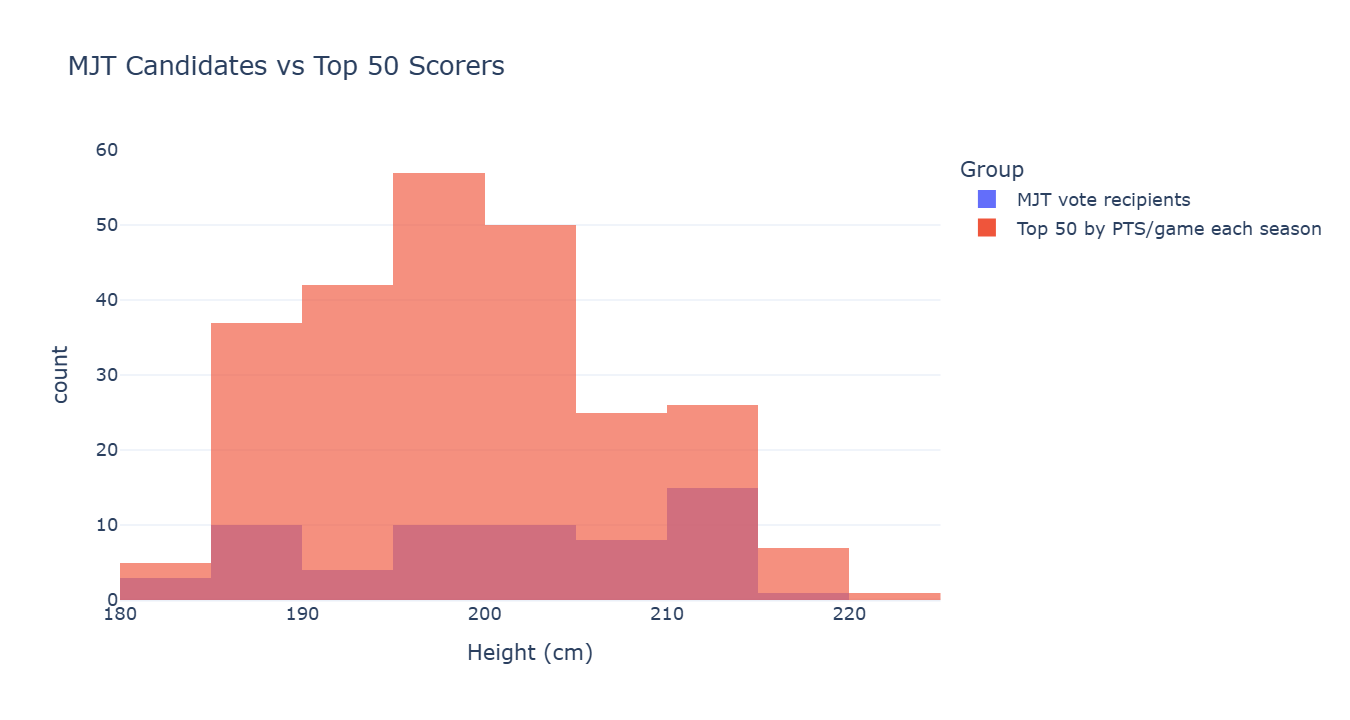

In [14]:
import plotly.express as px

height_plot_data = pd.concat([
    mjt5[["Ht_CM"]].rename(columns={"Ht_CM":"Height_CM"}).assign(Group="MJT vote recipients"),
    top50[["Height_CM"]].assign(Group="Top 50 by PTS/game each season")
], ignore_index=True).dropna(subset=["Height_CM"])

fig_height = px.histogram(
    height_plot_data, x="Height_CM", color="Group", barmode="overlay",
    opacity=0.65, nbins=14,
    labels={"Height_CM":"Height (cm)", "count":"Count", "Group":"Group"},
    title=" MJT Candidates vs Top 50 Scorers"
)
fig_height.update_layout(template="plotly_white", legend_title_text="Group")
fig_height.show()


In [15]:
champion_info = {2023: ("Denver Nuggets", "DEN"), 2024: ("Boston Celtics", "BOS")}
champion_groups, top15_groups = [], []
for season, (team_name, team_code) in champion_info.items():
    season_stats = pg_unique[pg_unique["Season"].eq(season)].copy()
    roster = rosters[(rosters["Season"].eq(season)) & (rosters["Team"].eq(team_code))].copy()
    active = roster[roster["Player"].isin(set(season_stats["Player"]))].copy()
    active = active.merge(season_stats[["Player","PTS","G"]], on="Player", how="left", suffixes=("_roster","_stats"))
    active["Height_CM"] = active["Ht_CM"]
    active["Season"] = season
    active["Group"] = f"{team_name} active players"
    champion_groups.append(active)

    top15 = season_stats.sort_values("PTS", ascending=False).head(15).copy()
    exp = roster[["Player","Exp_Numeric","Ht_CM"]].drop_duplicates("Player").rename(columns={"Exp_Numeric":"Experience_Years","Ht_CM":"Roster_Height_CM"})
    top15 = top15.merge(exp, on="Player", how="left")
    top15["Height_CM"] = top15["Roster_Height_CM"].combine_first(top15["Height_CM"])
    top15["Season"] = season
    top15["Group"] = "Top 15 by PTS/game"
    top15_groups.append(top15)

champ_df = pd.concat(champion_groups, ignore_index=True)
top15_df = pd.concat(top15_groups, ignore_index=True)
rows = []
for season, (team_name, _) in champion_info.items():
    for group, df in [(f"{team_name} active players",champ_df[champ_df["Season"].eq(season)]),
                      ("Top 15 by PTS/game",top15_df[top15_df["Season"].eq(season)])]:
        for metric, col in [("Experience (years)","Exp_Numeric" if "Exp_Numeric" in df.columns else "Experience_Years"),
                            ("Height (cm)","Height_CM")]:
            if col in df:
                rows.append({"Season":season,"Group":group,"Metric":metric,**descriptive_stats(df[col]).to_dict()})
comparison_summary = pd.DataFrame(rows)
display(comparison_summary.round(2))


,Season,Group,Metric,N,Mean,Median,Std,Min,Q1,Q3,Max
0,2023,Denver Nuggets active players,Experience (years),18.0,5.61,4.50,4.74,0.00,2.25,8.75,14.00
1,2023,Denver Nuggets active players,Height (cm),18.0,199.53,201.93,8.28,182.88,193.68,205.10,210.82
2,2023,Top 15 by PTS/game,Experience (years),0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023,Top 15 by PTS/game,Height (cm),15.0,197.78,198.12,9.59,187.96,187.96,204.47,213.36
4,2024,Boston Celtics active players,Experience (years),19.0,4.68,3.00,4.26,0.00,2.00,6.00,16.00
5,2024,Boston Celtics active players,Height (cm),19.0,200.66,200.66,8.80,185.42,195.58,203.20,218.44
6,2024,Top 15 by PTS/game,Experience (years),1.0,6.00,6.00,NaN,6.00,6.00,6.00,6.00
7,2024,Top 15 by PTS/game,Height (cm),15.0,197.95,195.58,9.91,187.96,187.96,207.01,213.36


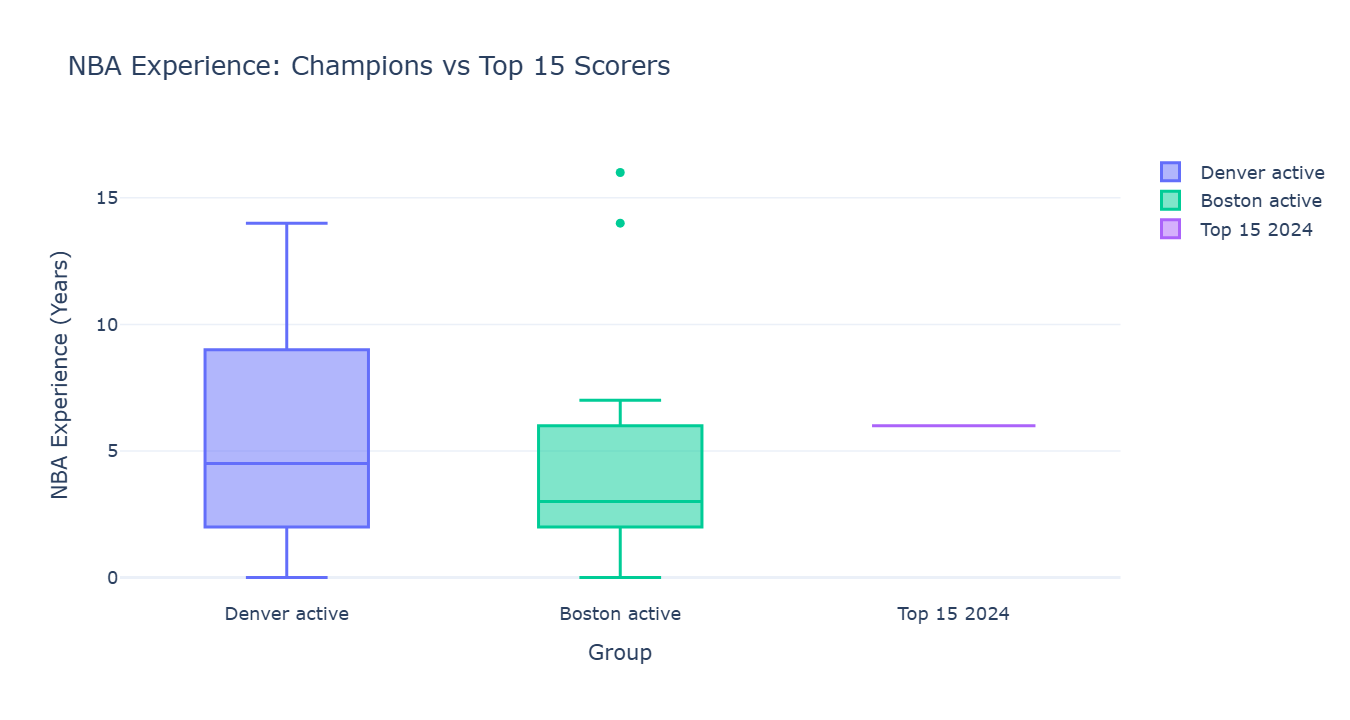

In [16]:
import plotly.graph_objects as go

labels = ["Denver active", "Top 15 2023", "Boston active", "Top 15 2024"]
exp_data = [
    pd.to_numeric(champ_df[champ_df["Season"].eq(2023)]["Exp_Numeric"], errors="coerce").dropna(),
    pd.to_numeric(top15_df[top15_df["Season"].eq(2023)]["Experience_Years"], errors="coerce").dropna(),
    pd.to_numeric(champ_df[champ_df["Season"].eq(2024)]["Exp_Numeric"], errors="coerce").dropna(),
    pd.to_numeric(top15_df[top15_df["Season"].eq(2024)]["Experience_Years"], errors="coerce").dropna()
]

fig_exp = go.Figure()
for label, values in zip(labels, exp_data):
    fig_exp.add_trace(go.Box(y=values, name=label, boxpoints="outliers"))
fig_exp.update_layout(
    title="NBA Experience: Champions vs Top 15 Scorers",
    yaxis_title="NBA Experience (Years)", xaxis_title="Group", template="plotly_white"
)
fig_exp.show()


In [17]:
mjt_pos = mjt5[["Season","Player","Share","Rank_Numeric"]].merge(
    pg_unique[["Season","Player","Pos","PTS","AST","TRB"]], on=["Season","Player"], how="left")
pg_mjt = mjt_pos[mjt_pos["Pos"].astype(str).str.upper().str.contains("PG", regex=False, na=False)].copy()
pg_recommendations = pg_mjt.groupby("Player").agg(
    MJT_Appearances=("Season","nunique"),
    Seasons=("Season",lambda x: ", ".join(map(str, sorted(set(x))))),
    Total_Share=("Share","sum"), Avg_PTS=("PTS","mean"), Avg_AST=("AST","mean"), Avg_TRB=("TRB","mean")
).reset_index().sort_values(["MJT_Appearances","Total_Share","Avg_AST"],ascending=[False,False,False])
pg_recommendations.insert(0,"Priority",range(1,len(pg_recommendations)+1))
display(pg_recommendations.head(10).round(3))


,Priority,Player,MJT_Appearances,Seasons,Total_Share,Avg_PTS,Avg_AST,Avg_TRB
9,1,Luka Dončić,5,"2020, 2021, 2022, 2023, 2024",0.968,30.240,8.780,8.860
12,2,Stephen Curry,3,"2021, 2022, 2023",0.458,28.967,6.133,5.600
1,3,Chris Paul,3,"2020, 2021, 2022",0.166,16.233,8.800,4.633
8,4,LeBron James,2,"2020, 2021",0.747,25.150,9.000,7.750
11,5,Shai Gilgeous-Alexander,2,"2023, 2024",0.692,30.750,5.850,5.150
6,6,Jalen Brunson,2,"2023, 2024",0.144,26.350,6.450,3.550
2,7,Damian Lillard,2,"2020, 2021",0.061,29.400,7.750,4.250
5,8,Ja Morant,2,"2022, 2023",0.011,26.800,7.400,5.800
4,9,Derrick Rose,1,2021,0.010,14.700,4.200,2.600
10,10,Russell Westbrook,1,2021,0.005,22.200,11.700,11.500


In [18]:
height_summary.to_csv("height_summary_engineered.csv")
comparison_summary.to_csv("champion_comparison_summary_engineered.csv", index=False)
pg_recommendations.to_csv("pg_mjt_recommendations_engineered.csv", index=False)
print("CSV summary files saved.")


CSV summary files saved.


---
# Phase 3 - Part 2: Hypothesis Testing

# Hypothesis Test


## Hypothesis Test 1: Change in Mean Agility


$$
H_0: \mu_B \leq \mu_A
$$


$$
H_1: \mu_B > \mu_A
$$


In [19]:
import pandas as pd
import numpy as np
import plotly

In [20]:
from scipy.stats import shapiro
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import base64
from IPython.display import display

if 'go' in globals() and hasattr(go.Figure, 'show') and go.Figure.show != _universal_fig_show:
    go.Figure.show = _universal_fig_show

def check_normality(data, group_name):
    stat, p_value = shapiro(data)
    if p_value > 0.05:
        print(f"{group_name}: Data is normal (p={p_value:.4f}).")
    else:
        print(f"{group_name}: Data is not normal (p={p_value:.4f}).")

def plot_histogram(data, title, x_label, color="#636EFA", bins=20):
    fig = px.histogram(
        x=data,
        nbins=bins,
        title=title,
        labels={"x": x_label, "count": "Frequency"},
        template="plotly_white",
        color_discrete_sequence=[color])
    fig.update_layout(
        title_x=0.5,
        xaxis_title=x_label,
        yaxis_title="Frequency",
        bargap=0.1)
    fig.show()


### Data Preparation for Hypothesis Testing


In [21]:
df = pd.read_csv("rosters_cleaned_and_engineered.csv")
df.head()

,Season,Team,No.,Player,Pos,Ht,Wt,Birth Date,Birth,Exp,...,Wt_KG,Exp_Numeric,Birth_Date_DT,No_Numeric,Agility_Metric,BMI,Rookie_Flag,Roster_Exp_Tier,Estimated_Age,Innate_Ability_Roster
0,1980,ATL,50,John Brown,SF,6-7,220,"December 14, 1951",deDE,6,...,99.79,6,1951-12-14,50.0,2.0108,24.78,0,Veteran,29,0.2069
1,1980,ATL,14,Charlie Criss,PG,5-8,165,"November 6, 1948",usUS,2,...,74.84,2,1948-11-06,14.0,2.3079,25.09,0,Developing,32,0.0625
2,1980,ATL,22,John Drew,SF,6-6,205,"September 30, 1954",usUS,5,...,92.99,5,1954-09-30,22.0,2.1306,23.69,0,Veteran,26,0.1923
3,1980,ATL,25,Terry Furlow,SG,6-4,190,"October 18, 1954",usUS,3,...,86.18,3,1954-10-18,25.0,2.2400,23.13,0,Developing,26,0.1154
4,1980,ATL,21,Jack Givens,SF,6-5,205,"September 21, 1956",usUS,1,...,92.99,1,1956-09-21,21.0,2.1032,24.31,0,Developing,24,0.0417


In [22]:
seasons = [2020, 2021, 2022, 2023]
df_alternative = df[df["Season"].isin(seasons)].copy()
top_20 = df_alternative.groupby("Season", sort=True).head(20)

top_20.head()

,Season,Team,No.,Player,Pos,Ht,Wt,Birth Date,Birth,Exp,...,Wt_KG,Exp_Numeric,Birth_Date_DT,No_Numeric,Agility_Metric,BMI,Rookie_Flag,Roster_Exp_Tier,Estimated_Age,Innate_Ability_Roster
683,2020,ATL,95,DeAndre' Bembry,SG,6-5,210,"July 4, 1994",usUS,3,...,95.25,3,1994-07-04,95.0,2.0533,24.90,0,Developing,26,0.1154
684,2020,ATL,4,Charlie Brown Jr.,SG,6-6,199,"February 2, 1997",usUS,R,...,90.26,0,1997-02-02,4.0,2.1950,23.00,1,Rookie,23,0.0000
685,2020,ATL,15,Vince Carter,PF,6-6,220,"January 26, 1977",usUS,21,...,99.79,21,1977-01-26,15.0,1.9854,25.42,0,Veteran,43,0.4884
686,2020,ATL,20,John Collins,PF,6-9,226,"September 23, 1997",usUS,2,...,102.51,2,1997-09-23,20.0,2.0070,24.22,0,Developing,23,0.0870
687,2020,ATL,33,Allen Crabbe,SG,6-5,212,"April 9, 1992",usUS,6,...,96.16,6,1992-04-09,33.0,2.0339,25.14,0,Veteran,28,0.2143


In [23]:
group_A = top_20[top_20["Season"].isin([2020, 2021])]["Agility_Metric"]
group_B = top_20[top_20["Season"].isin([2022, 2023])]["Agility_Metric"]

print("Group A mean:", group_A.mean())
print("Group A standard deviation:", group_A.std())
print("------------------")
print("Group B mean:", group_B.mean())
print("Group B standard deviation:", group_B.std())

Group A mean: 2.033045
Group A standard deviation: 0.16727238641332962
------------------
Group B mean: 2.066865
Group B standard deviation: 0.1764256414150674


### Testing the Independence of Groups A and B


In [24]:
players_A = set(top_20[top_20["Season"].isin([2020, 2021])]["Player"])
players_B = set(top_20[top_20["Season"].isin([2022, 2023])]["Player"])

print("Players appearing in both groups:", len(players_A.intersection(players_B)))


Players appearing in both groups: 12


### Testing for Normality


In [25]:
check_normality(group_A, "Group A")
check_normality(group_B, "Group B")

Group A: Data is not normal (p=0.0160).
Group B: Data is not normal (p=0.0116).


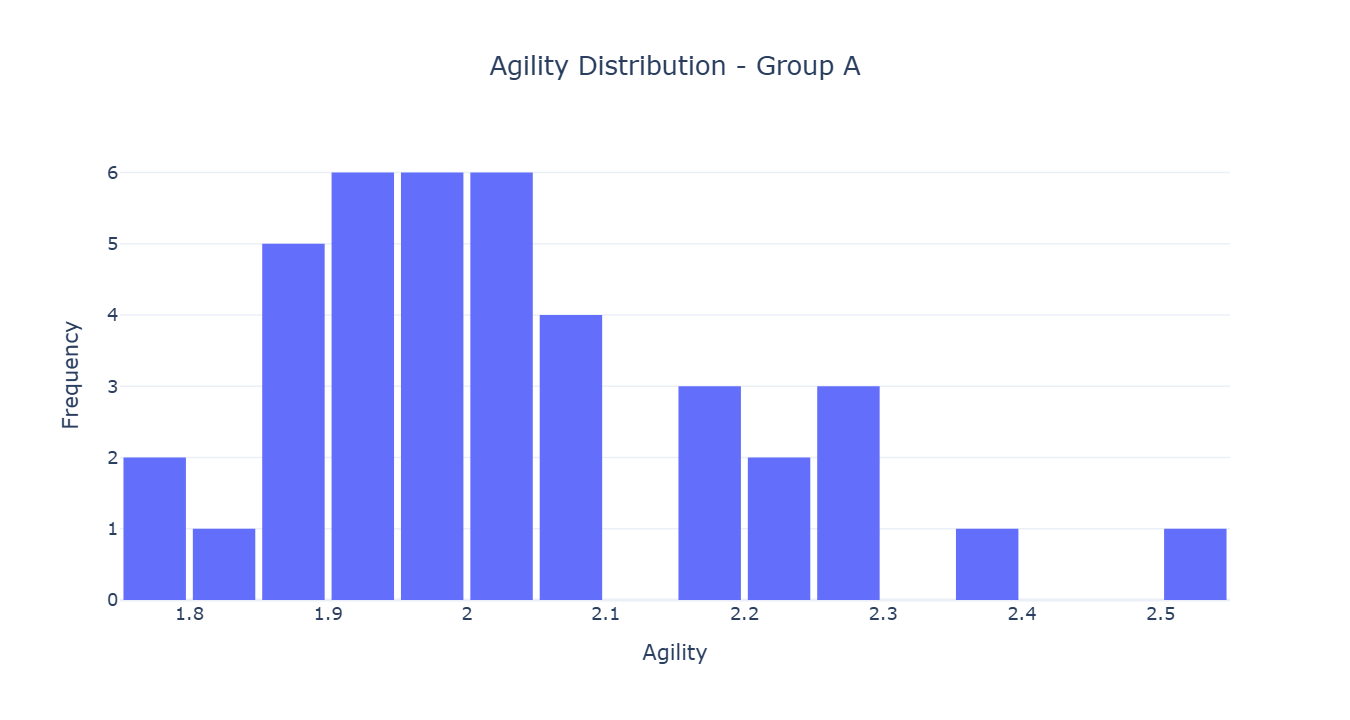

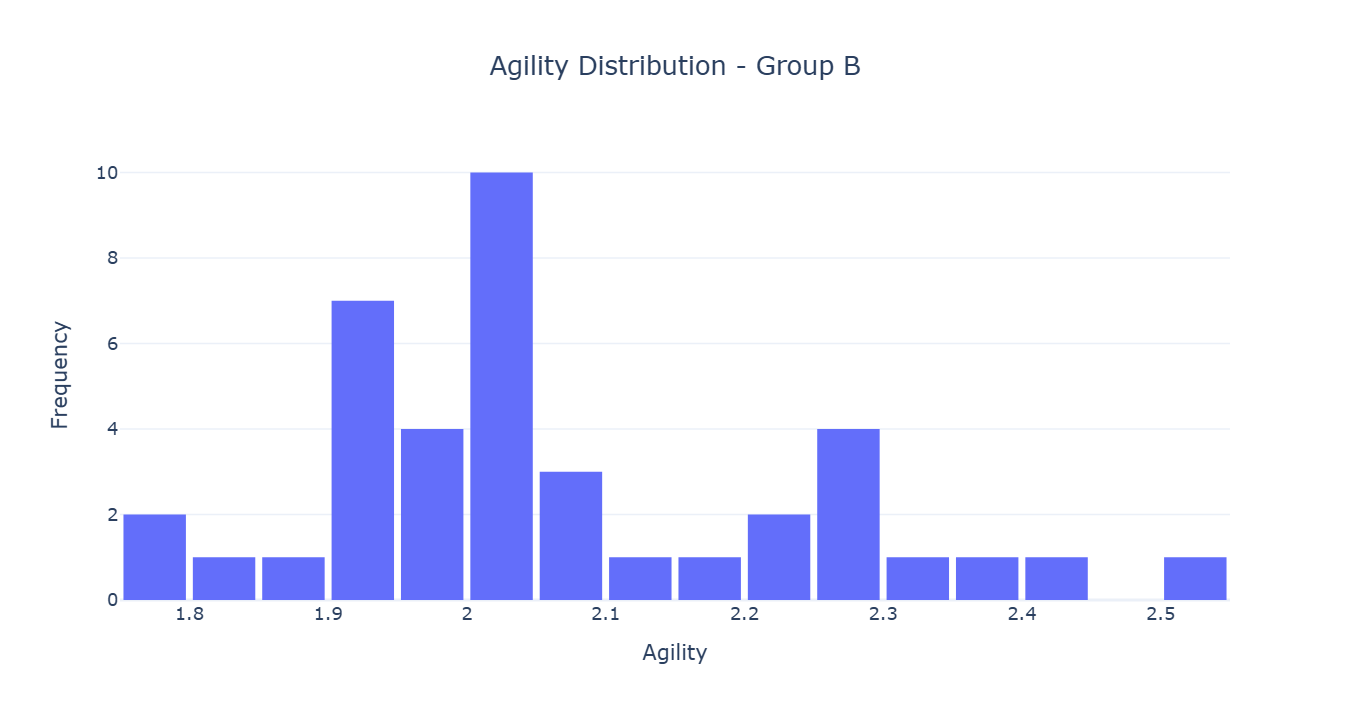

In [26]:
plot_histogram(group_A, title="Agility Distribution - Group A",  x_label="Agility")
plot_histogram(group_B, title="Agility Distribution - Group B", x_label="Agility")

### Wilcoxon Signed-Rank Test


In [27]:
from scipy.stats import wilcoxon

n = min(len(group_A), len(group_B))

group_A = group_A.iloc[:n]
group_B = group_B.iloc[:n]

stat, p_value = wilcoxon(group_B, group_A, alternative="greater")

print("Wilcoxon Signed-Rank Test")
print("Test statistic:", stat)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Wilcoxon Signed-Rank Test
Test statistic: 468.0
P-value: 0.2178119865112047
Fail to reject H0


## Hypothesis Test 2: Change in Players’ Innate Ability


### Data Preparation: Comparing Innate Ability Across Seasons


In [28]:
import pandas as pd
import numpy as np
from scipy import stats

rosters = pd.read_csv("rosters_cleaned_and_engineered.csv")
champions = pd.read_csv("cross_champions_vs_top_players.csv")

In [29]:
rosters.head()

,Season,Team,No.,Player,Pos,Ht,Wt,Birth Date,Birth,Exp,...,Wt_KG,Exp_Numeric,Birth_Date_DT,No_Numeric,Agility_Metric,BMI,Rookie_Flag,Roster_Exp_Tier,Estimated_Age,Innate_Ability_Roster
0,1980,ATL,50,John Brown,SF,6-7,220,"December 14, 1951",deDE,6,...,99.79,6,1951-12-14,50.0,2.0108,24.78,0,Veteran,29,0.2069
1,1980,ATL,14,Charlie Criss,PG,5-8,165,"November 6, 1948",usUS,2,...,74.84,2,1948-11-06,14.0,2.3079,25.09,0,Developing,32,0.0625
2,1980,ATL,22,John Drew,SF,6-6,205,"September 30, 1954",usUS,5,...,92.99,5,1954-09-30,22.0,2.1306,23.69,0,Veteran,26,0.1923
3,1980,ATL,25,Terry Furlow,SG,6-4,190,"October 18, 1954",usUS,3,...,86.18,3,1954-10-18,25.0,2.2400,23.13,0,Developing,26,0.1154
4,1980,ATL,21,Jack Givens,SF,6-5,205,"September 21, 1956",usUS,1,...,92.99,1,1956-09-21,21.0,2.1032,24.31,0,Developing,24,0.0417


In [30]:
champions.head()

,Season_Year,Champion_Team,Top15_Avg_Height_CM,Top15_Avg_Age,Top15_Avg_Agility,Top15_Leading_Scorer,Top15_Max_PTS
0,2026,New York Knicks,198.0,29.5,1.9958,Luka Dončić,2143.0
1,2025,Oklahoma City Thunder,198.5,28.1,2.0623,Shai Gilgeous-Alexander,2484.0
2,2024,Boston Celtics,199.5,28.6,1.9965,Luka Dončić,2370.0
3,2023,Denver Nuggets,198.5,26.5,2.0235,Jayson Tatum,2225.0
4,2022,Golden State Warriors,201.7,27.2,1.9795,Trae Young,2155.0


In [31]:
print(sorted(rosters["Season"].dropna().unique()))
print(sorted(champions["Season_Year"].dropna().unique()))

[np.int64(1980), np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026), np.int64(2027)]
[np.int64(1980), np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int

In [32]:
print("Seasons in rosters:")
print(sorted(rosters["Season"].unique()))
print("\nSeasons in champions:")
print(sorted(champions["Season_Year"].unique()))

Seasons in rosters:
[np.int64(1980), np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(1991), np.int64(1992), np.int64(1993), np.int64(1994), np.int64(1995), np.int64(1996), np.int64(1997), np.int64(1998), np.int64(1999), np.int64(2000), np.int64(2001), np.int64(2002), np.int64(2003), np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026), np.int64(2027)]

Seasons in champions:
[np.int64(1980), np.int64(1981), np.int64(1982), np.int64(1983), np.int64(1984), np.int64(1985), np.int64(1986), np.int64(1987), np.int64(1988), np.int64(1989), np.int64(1990), np.int64(19

In [33]:
team_names = {
    "ATL": "Atlanta Hawks",
    "BOS": "Boston Celtics",
    "NJN": "New Jersey Nets",
    "CHA": "Charlotte Hornets",
    "CHI": "Chicago Bulls",
    "CLE": "Cleveland Cavaliers",
    "DAL": "Dallas Mavericks",
    "DEN": "Denver Nuggets",
    "DET": "Detroit Pistons",
    "GSW": "Golden State Warriors",
    "HOU": "Houston Rockets",
    "IND": "Indiana Pacers",
    "LAC": "Los Angeles Clippers",
    "LAL": "Los Angeles Lakers",
    "MEM": "Memphis Grizzlies",
    "MIA": "Miami Heat",
    "MIL": "Milwaukee Bucks",
    "MIN": "Minnesota Timberwolves",
    "NOP": "New Orleans Pelicans",
    "NYK": "New York Knicks",
    "OKC": "Oklahoma City Thunder",
    "ORL": "Orlando Magic",
    "PHI": "Philadelphia 76ers",
    "PHX": "Phoenix Suns",
    "POR": "Portland Trail Blazers",
    "SAC": "Sacramento Kings",
    "SAS": "San Antonio Spurs",
    "TOR": "Toronto Raptors",
    "UTA": "Utah Jazz",
    "WAS": "Washington Wizards",
    "BKN": "Brooklyn Nets",
    "SEA": "Seattle SuperSonics",
    "VAN": "Vancouver Grizzlies",
    "NOH": "New Orleans Hornets",
    "NOK": "New Orleans/Oklahoma City Hornets",
    "WSB": "Washington Bullets",
    "KCK": "Kansas City Kings",
    "SDC": "San Diego Clippers",
    "BUF": "Buffalo Braves",
    "PHO": "Phoenix Suns",
    "CHH": "Charlotte Hornets",
    "UTH": "Utah Jazz"
}

rosters["Team_Full"] = rosters["Team"].map(team_names)


In [34]:
merged = rosters.merge(champions[["Season_Year", "Champion_Team"]].drop_duplicates(),
    left_on="Season", right_on="Season_Year", how="inner")

champion_players = merged[merged["Team_Full"] == merged["Champion_Team"]].copy()

champion_players.groupby("Season").agg(
    Number_of_Players=("Player", "nunique"),
    Mean_Innate_Ability=("Innate_Ability_Roster", "mean"))

,Number_of_Players,Mean_Innate_Ability
Season,,
1980,15,0.124540
1981,12,0.104567
1982,14,0.139857
1983,14,0.110621
1984,12,0.158317
1985,14,0.167450
1986,13,0.172815
1987,13,0.150838
1988,15,0.170893


In [35]:
print(sorted(champion_players["Season"].unique())[-4:])

[np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]


In [36]:
player_seasons = champion_players.groupby("Player")["Season"].nunique()
print(player_seasons.value_counts().sort_index())

Season
1    379
2     77
3     36
4     13
5      9
6      2
7      1
Name: count, dtype: int64


In [37]:
recent_seasons = [2025, 2026]
previous_seasons = [2023, 2024]

recent_players = champion_players[champion_players["Season"].isin(recent_seasons)].copy()
previous_players = champion_players[champion_players["Season"].isin(previous_seasons)].copy()

### Testing the Independence of Innate Ability Across Seasons


In [38]:
recent_names = set(recent_players["Player"])
previous_names = set(previous_players["Player"])

print("Number of recent players:", len(recent_names))
print("Number of previous players", len(previous_names))
print("Number of common players:", len(recent_names.intersection(previous_names)))

Number of recent players: 38
Number of previous players 37
Number of common players: 0


### Testing the Normality of Innate Ability Across Seasons


In [39]:
check_normality(recent_players["Innate_Ability_Roster"], "Recent Seasons")
check_normality(previous_players["Innate_Ability_Roster"], "Previous Seasons")

Recent Seasons: Data is not normal (p=0.0042).
Previous Seasons: Data is not normal (p=0.0479).


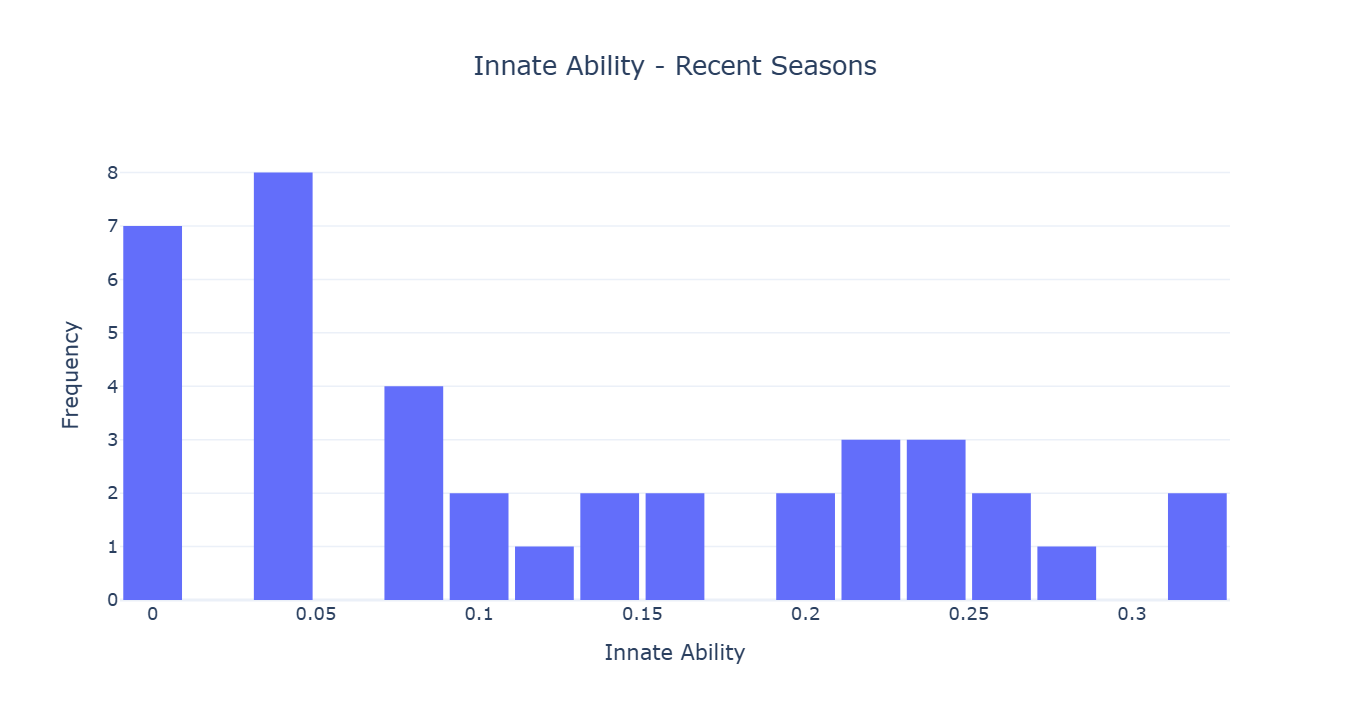

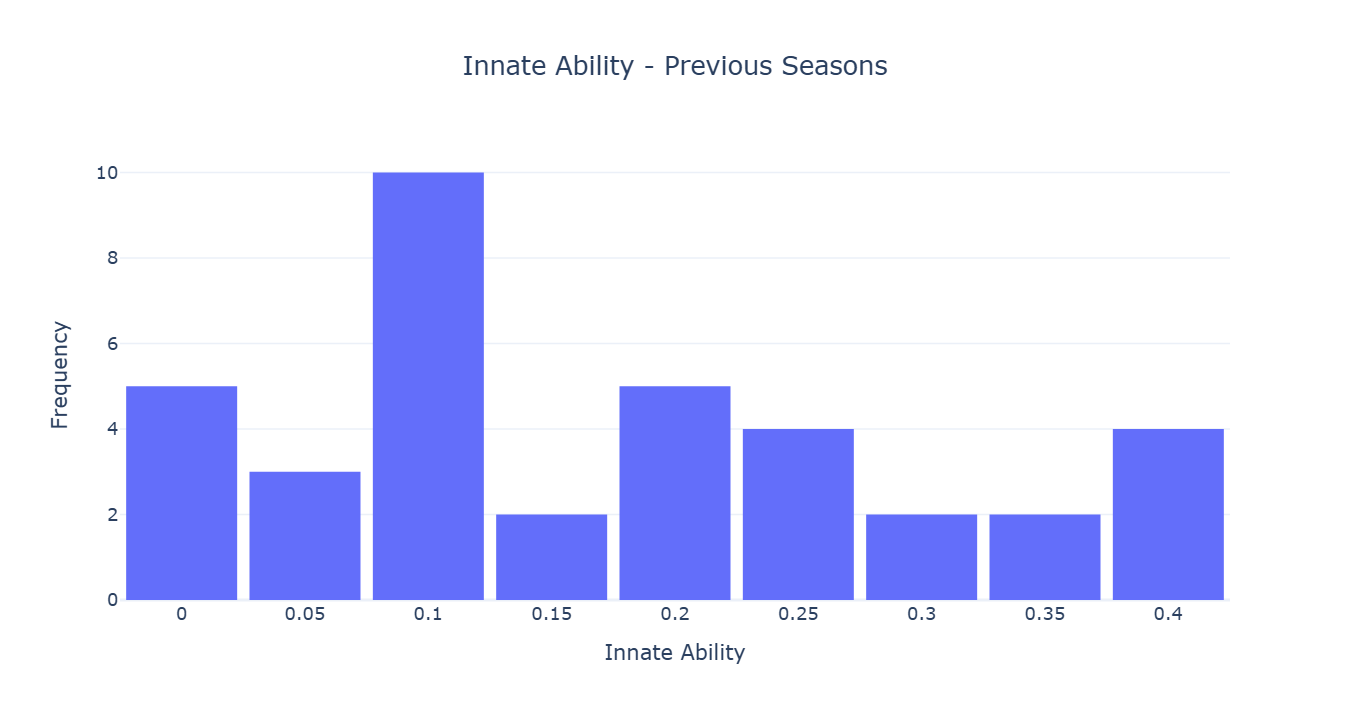

In [40]:
plot_histogram(recent_players["Innate_Ability_Roster"],
    title="Innate Ability - Recent Seasons",
    x_label="Innate Ability")

plot_histogram(previous_players["Innate_Ability_Roster"],
    title="Innate Ability - Previous Seasons",
    x_label="Innate Ability")


### Mann–Whitney U Test: Comparing Innate Ability Across Seasons


In [41]:

from scipy.stats import mannwhitneyu

recent_ability = recent_players["Innate_Ability_Roster"]
previous_ability = previous_players["Innate_Ability_Roster"]

statistic, p_value = mannwhitneyu(recent_ability, previous_ability, alternative="greater")

print("Mann-Whitney U statistic:", statistic)
print("P-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")

Mann-Whitney U statistic: 557.5
P-value: 0.956671164336633
Fail to reject H0


---
# Phase 4 (Bonus): Player Clustering & Salary Hypothesis Analysis

## NBA Player Performance Clustering and Salary Analysis

### Discovering Player Groups Using K-Means and Testing Salary Differences


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from scipy import stats

### Load and Explore the Dataset


In [43]:
data = pd.read_csv("cross_salary_vs_performance.csv")

data.head()

,Season,Team,Rk,Player,Salary,Salary_Numeric,Salary_Millions,Salary_Log,Salary_Tier,Team_Payroll_Share,...,WS,VORP,BPM,G,MP,PTS,Dollars_Per_Win_Share,Dollars_Per_Point,Value_Over_Contract_Index,Contract_Performance_Class
0,1985,ATL,1,Tree Rollins,"$678,000",678000.0,0.678,13.427,Minimum (<3M),0.2359,...,3.8,1.2,0.7,70.0,1750.0,439.0,178421.0,1544.0,17.699,Surplus Value / Bargain
1,1985,ATL,2,Eddie Johnson,"$491,000",491000.0,0.491,13.104,Minimum (<3M),0.1708,...,4.2,0.8,-0.7,73.0,2367.0,1193.0,116905.0,412.0,16.293,Surplus Value / Bargain
2,1985,ATL,3,Dominique Wilkins,"$460,000",460000.0,0.460,13.039,Minimum (<3M),0.1601,...,7.6,3.2,2.2,81.0,3023.0,2217.0,60526.0,207.0,69.565,Massive Bargain / High Surplus
3,1985,ATL,4,Sly Williams,"$450,000",450000.0,0.450,13.017,Minimum (<3M),0.1566,...,0.5,0.1,-1.6,34.0,867.0,417.0,900000.0,1079.0,2.222,Surplus Value / Bargain
4,1985,ATL,5,Cliff Levingston,"$200,000",200000.0,0.200,12.206,Minimum (<3M),0.0696,...,4.7,1.0,0.0,74.0,2017.0,727.0,42553.0,275.0,50.000,Surplus Value / Bargain


In [44]:
data[["PER", "WS", "VORP", "BPM", "G", "MP", "PTS", "Salary_Log"]].describe()

,PER,WS,VORP,BPM,G,MP,PTS,Salary_Log
count,15822.000000,15822.000000,15822.000000,15822.000000,15822.000000,15822.000000,15822.000000,15822.000000
mean,13.031633,2.593547,0.648578,-1.475616,49.641259,1187.231134,510.667299,13.843422
std,6.300937,3.041549,1.396777,4.895153,26.607115,921.089479,492.433323,3.163218
min,-45.200000,-2.100000,-2.600000,-81.400000,1.000000,0.000000,0.000000,0.000000
25%,10.100000,0.200000,-0.100000,-3.300000,26.000000,328.000000,103.000000,13.349250
50%,13.000000,1.600000,0.100000,-1.200000,56.000000,1057.000000,366.500000,14.417000
75%,16.200000,4.000000,1.000000,0.700000,74.000000,1936.000000,785.000000,15.408000
max,133.800000,21.200000,12.500000,242.200000,82.000000,3533.000000,3041.000000,17.952000


In [45]:
features = ["PER", "WS", "VORP", "BPM", "G", "MP", "PTS"]
X = data[features].copy()
X.head()

,PER,WS,VORP,BPM,G,MP,PTS
0,12.3,3.8,1.2,0.7,70.0,1750.0,439.0
1,15.8,4.2,0.8,-0.7,73.0,2367.0,1193.0
2,20.9,7.6,3.2,2.2,81.0,3023.0,2217.0
3,12.9,0.5,0.1,-1.6,34.0,867.0,417.0
4,14.6,4.7,1.0,0.0,74.0,2017.0,727.0


### Data Standardization


In [46]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled[:5]

array([[-0.11611864,  0.39666995,  0.39479414,  0.44445703,  0.76518573,
         0.61100106, -0.14554166],
       [ 0.43937183,  0.52818603,  0.10841159,  0.15845078,  0.87794109,
         1.28088115,  1.38567849],
       [ 1.2488008 ,  1.64607275,  1.82670687,  0.7508923 ,  1.17862205,
         1.99310374,  3.46521356],
       [-0.02089171, -0.68833775, -0.39275786, -0.02541038, -0.5878786 ,
        -0.3476766 , -0.19021917],
       [ 0.24891795,  0.69258114,  0.25160287,  0.3014539 ,  0.91552621,
         0.90088434,  0.43932758]])

### Determine the Number of Clusters


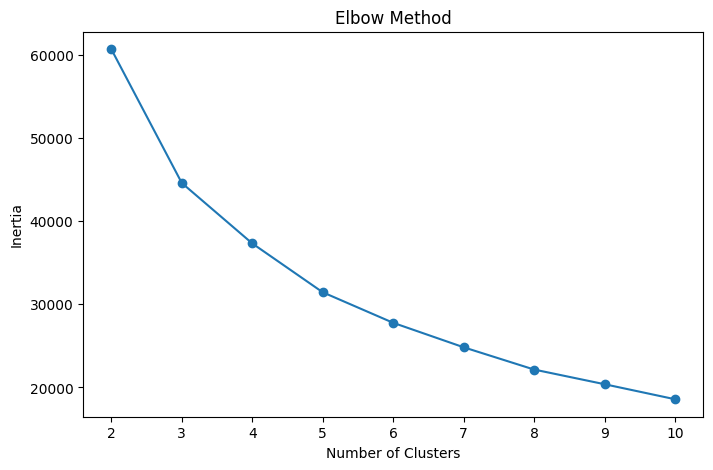

In [47]:

inertia = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()



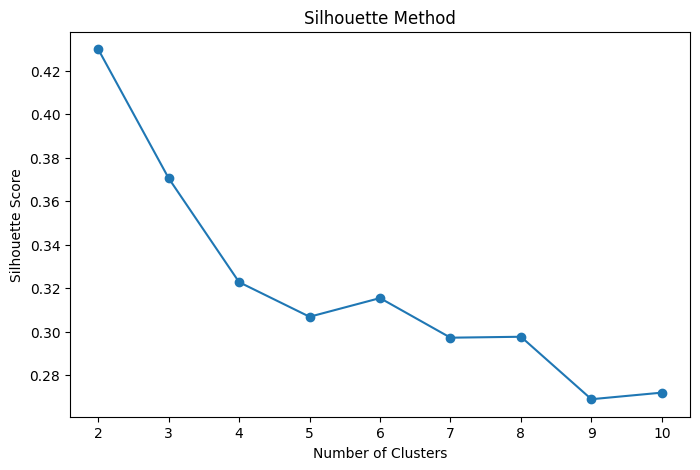

In [48]:

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Method")
plt.show()



### Building the K-Means Clustering Model


In [49]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

data["Cluster"] = kmeans.fit_predict(X_scaled)

data["Cluster"].value_counts()

Cluster
1    10048
0     5774
Name: count, dtype: int64

### Analyzing Cluster Characteristics


In [50]:
data.groupby("Cluster")[["PER", "WS", "VORP", "BPM", "G", "MP", "PTS"]].mean()


,PER,WS,VORP,BPM,G,MP,PTS
Cluster,,,,,,,
0,16.842917,5.703169,1.848424,1.337097,72.709906,2188.403187,1026.190509
1,10.841511,0.806628,-0.040904,-3.091919,36.385052,611.915904,214.426154


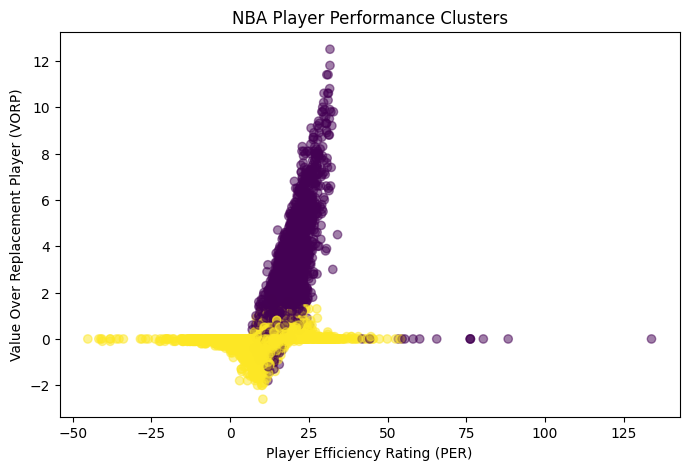

In [51]:
plt.figure(figsize=(8, 5))
plt.scatter(data["PER"], data["VORP"],
    c=data["Cluster"], alpha=0.5)

plt.xlabel("Player Efficiency Rating (PER)")
plt.ylabel("Value Over Replacement Player (VORP)")
plt.title("NBA Player Performance Clusters")
plt.show()

### Comparing Salaries Across Clusters


In [52]:
data.groupby("Cluster")["Salary_Log"].describe()

,count,mean,std,min,25%,50%,75%,max
Cluster,,,,,,,,
0,5774.0,15.043493,1.367842,0.0,14.20475,15.084,16.04575,17.903
1,10048.0,13.153811,3.657596,0.0,12.83500,13.998,14.91400,17.952


In [53]:
from scipy import stats

group_0 = data[data["Cluster"] == 0]["Salary_Log"].dropna()
group_1 = data[data["Cluster"] == 1]["Salary_Log"].dropna()

t_stat, p_value = stats.ttest_ind(group_0, group_1, equal_var=False)

print("T-statistic:", t_stat)
print("P-value:", p_value)


alpha = 0.05
if p_value < alpha:
    print("Reject H0")
else:
    print("Fail to reject H0")


T-statistic: 46.44415717517513
P-value: 0.0
Reject H0


<Figure size 800x500 with 0 Axes>

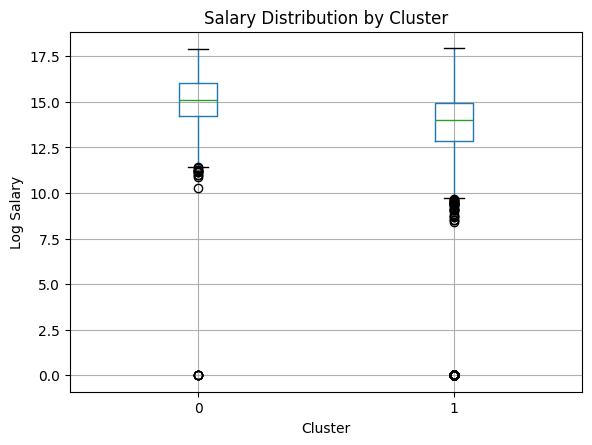

In [54]:
plt.figure(figsize=(8, 5))
data.boxplot(column="Salary_Log", by="Cluster")
plt.title("Salary Distribution by Cluster")
plt.suptitle("")
plt.xlabel("Cluster")
plt.ylabel("Log Salary")
plt.show()

---
### End of Pipeline: NBA Analytics Master Pipeline (Phases 1 to 4 Complete)